# Сложные задачи, ось A: перефразированный вопрос

**Вопрос ноутбука:** сохраняют ли головы, найденные на простой задаче, свою роль, когда вопрос перестаёт дословно повторять иглу.

Игла и стог те же на всех уровнях оси; меняется только вопрос. Вставок нет.

| Часть | Что в ней | Прогоны |
|---|---|---|
| 1 | уровни оси и как проверяется ответ | — |
| 2 | **метрики ответов**: без маски и под масками; те же расчёты без семейства `oslo`; формулировки ответов (перефраз, замены, формы слов); формулировки без `oslo` | все четыре |
| 3 | **метрики голов**: те же графики, что на исходной задаче, по уровням; сохранение рейтинга; контроли | только без маски |

Прогоны: без маски (внимание сохранено, есть метрики голов) и три маски по рейтингу детекции на простой задаче — 40 и 60 лучших голов, 60 случайных. В каждом 3 семейства игл × 4 уровня × 11 длин × 6 глубин = 792 примера.

## 0. Настройки

In [1]:
import os, sys
sys.path.insert(0, os.path.abspath(".."))   # корень репозитория: ноутбук лежит в vizual/

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from vizual import data, hard, plots, style

RUNS = "results/new/qwen3_hard_fast/A/*"      # все прогоны оси
NONE = "results/new/qwen3_hard_fast/A/none"   # прогон без маски: в нём метрики голов
DETECT = "results/new/qwen3_detect"           # детекция на простой задаче: рейтинг, по которому строились маски

METRIC = "copy_recall"    # скор головы: copy_recall — как в статье, copy_count — как в коде авторов
THRESHOLD = 0.1           # порог retrieval-головы из статьи
SAVE = False              # сохранять рисунки в vizual/figures/

style.use(scale=1.0, dpi=110)
pd.set_option("display.max_colwidth", 220)

def show(ax, name):
    if SAVE:
        plots.save(np.ravel(ax)[0].figure, name)
    plt.show()

def panels(n, width=5.0, height=4.2, extra=0.0, **kwargs):
    # n панелей в ряд, по одной на уровень
    return plt.subplots(1, n, figsize=style.size(width * n + extra, height), **kwargs)[1]

In [2]:
sweep = hard.load(RUNS)                       # ответы читаются из outputs/, метрики ответа считаются по ним
levels = sorted(sweep["level"].unique())
families = sorted(sweep["family"].unique())
none = sweep[sweep["run"] == "none"]
print(f"прогонов: {sweep['run'].nunique()}, примеров в каждом: {len(none)}; семейства: {families}; уровни: {levels}")

прогонов: 4, примеров в каждом: 792; семейства: ['cairo', 'lisbon', 'oslo']; уровни: ['A0', 'A1', 'A2', 'A3']


## 1. Уровни и как мы их проверяем

### 1.1. Что меняется на каждом уровне

| Уровень | Что сделано с вопросом | Что проверяет | Что нужно модели сверх поиска |
|---|---|---|---|
| **A0** | дословный: повторяет слова иглы | точка отсчёта для всех осей | ничего |
| **A1** | перефразирован, ключ (название города и места) сохранён | чистый перефраз: слова вопроса не совпадают со словами иглы | сопоставить синонимы (`visitor` → `guests`, `asked` → `requested`) |
| **A2** | дословный, но ключ заменён описанием («the Portuguese capital») | поиск без названного ключа | знать, что город — столица страны |
| **A3** | и перефраз, и замена ключа | оба усложнения вместе | и то и другое; эффекты не разделяются |

Чистый эффект перефраза — это A1 против A0; чистый эффект замены ключа — A2 против A0. A3 показывает только их сумму.

Игла, эталон и стог (эссе Пола Грэма) на всех четырёх уровнях одни и те же. Ключ иглы — реальный город, а ответ выдуман, поэтому по памяти ответить нельзя: верный ответ возможен только из текста.

In [3]:
# иглы, эталоны и факты, по которым проверяется ответ
first = none.drop_duplicates("family").set_index("family")
needles = {name: data.read_jsonl(data.path(f"data/needles_hard/{name}/axis_A.jsonl"))[0]["needle"] for name in families}
display(pd.DataFrame({"игла": needles, "эталон (ответ внутри иглы)": first["reference"],
                      "факты ответа (допустимые написания)": first["answer_key"].map(lambda key: "; ".join(" / ".join(fact) for fact in key))}))

# вопросы по уровням
display(none.drop_duplicates(["family", "level"]).pivot(index="level", columns="family", values="question"))

,игла,эталон (ответ внутри иглы),факты ответа (допустимые написания)
cairo,The famous soup of the Zahira Cafe in Cairo is cooked with smoked lemon peel and served in a bowl of black clay.,cooked with smoked lemon peel and served in a bowl of black clay,lemon peel; black clay
lisbon,Every visitor to the Lisbon Tram Museum is asked to ring the brass bell at the entrance and sign the guest book with a green pen.,ring the brass bell at the entrance and sign the guest book with a green pen,brass bell; guest book / guestbook
oslo,The oldest house in Oslo has a roof of red slate and a door painted with a white reindeer.,a roof of red slate and a door painted with a white reindeer,red slate; white reindeer / reindeer


family,cairo,lisbon,oslo
level,,,
A0,How is the famous soup of the Zahira Cafe in Cairo cooked and served?,What is every visitor to the Lisbon Tram Museum asked to do?,What does the oldest house in Oslo have?
A1,In what way do they prepare and present the well-known soup at the Zahira Cafe in Cairo?,What are guests of the Lisbon Tram Museum requested to do when they arrive?,How would you describe the most ancient building in Oslo?
A2,How is the famous soup of the Zahira Cafe in the Egyptian capital cooked and served?,What is every visitor to the tram museum of the Portuguese capital asked to do?,What does the oldest house in the Norwegian capital have?
A3,In what way do they prepare and present the well-known soup at the Zahira Cafe in Egypt's capital?,What are guests of the tram museum in Portugal's capital requested to do when they arrive?,How would you describe the most ancient building in Norway's capital?


### 1.2. Как проверяется ответ

Ответ считается верным не по совпадению строки с эталоном, а по **фактам**: в ответе должны быть названы оба ключевых факта иглы (таблица выше). Правило — `fact_class` из `rh/metrics.py`.

1. Ответ и факты приводятся к одному виду: нижний регистр, без пунктуации, Unicode NFKC.
2. Факт засчитан, если любое из его допустимых написаний стоит в ответе целым словом или фразой («guest book» или «guestbook»).
3. По числу найденных фактов ответ получает класс:

| Класс | Условие | Что это значит на оси A |
|---|---|---|
| **верно** | названы оба факта | модель нашла иглу и передала ответ, в любых словах |
| **частично** | назван один факт из двух | ответ найден, но оборван: «ring the brass bell» без гостевой книги |
| **иное** | ни одного факта | ответ не из иглы: отказ, рассуждение о тексте или ответ по памяти (на `oslo` — «Oslo Cathedral») |

Остальные классы правила (смешано, путаница, шум) требуют фактов вставок. На оси A вставок нет, поэтому эти классы здесь невозможны.

**Чего проверка не ловит.** Факт засчитывается только в написании из списка: «ring the bell» вместо «ring the brass bell» попадёт в «частично». И наоборот, названные факты не гарантируют, что остальная часть ответа верна.

### 1.3. Как проверяются головы

- Метрики голов считаются только в прогоне без маски: под маской внимание не сохранялось.
- В скор головы на уровне входят только примеры с **верным** ответом (по фактам). В статье условием был ROUGE-1 > 50; здесь он заменён, потому что на перефразе ROUGE занижен при верном ответе (раздел 2.1).
- Рейтинг голов **не переопределяется**: он взят из детекции на простой задаче. На каждом уровне смотрим, что с теми же головами.
- Уровни сравниваются на одних и тех же местах иглы (семейство, длина, глубина) — тех, где ответ верен на всех четырёх уровнях. Иначе разница между уровнями смешалась бы с разницей в наборах примеров.

# 2. Метрики ответов

| Метрика | Годится? | Почему |
|---|---|---|
| класс ответа по фактам | да, основная | не зависит от формулировки ответа |
| доля названных фактов | да | та же проверка без порога «оба факта» |
| ROUGE-1/2/3 recall | только как вспомогательная | эталон на всех уровнях один, близнецов нет, так что запрет из README (ответ с близнеца проходит порог) здесь не действует; но на A1 и A3 модель пересказывает ответ словами вопроса, и recall падает при верном ответе |
| точная фраза | нет | по той же причине: верный ответ «prepared with smoked lemon peel» вместо «cooked with…» не проходит |

## 2.1. Без маски

Насколько сама задача труднее без вмешательства в модель.

верные ответы без маски, %


level,A0,A1,A2,A3
family,,,,
cairo,100.0,100.0,100.0,100.0
lisbon,100.0,100.0,100.0,100.0
oslo,100.0,100.0,100.0,62.1


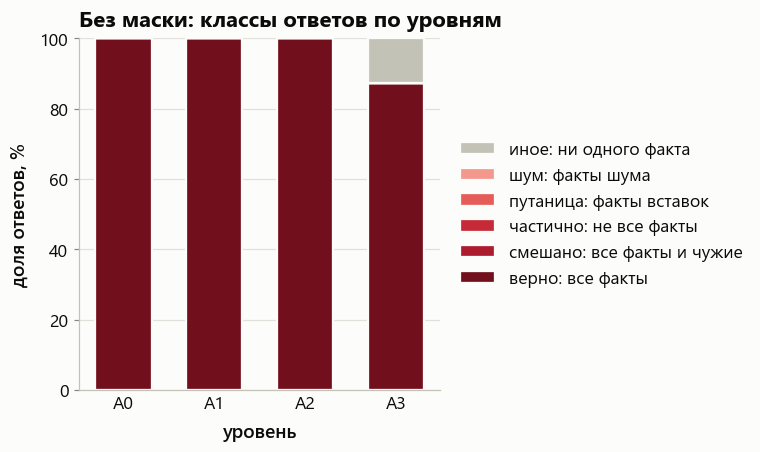

In [4]:
print("верные ответы без маски, %")
display(hard.by_level(none, by=("family", "level")))
show(plots.stacked(none, "level", "answer_class", hard.CLASSES, hard.CLASS_LABELS, xlabel="уровень", title="Без маски: классы ответов по уровням"), "A_none_classes")

### Почему ROUGE и точная фраза здесь вспомогательные

Только верные ответы без маски. Класс по фактам говорит «верно», а строковые метрики падают там, где модель пересказала ответ словами вопроса.

In [5]:
right = none[none["correct"]]
check = right.groupby(["family", "level"]).agg(верных=("id", "size"), точная_фраза=("exact", "mean"), rouge1=("rouge1_recall", "mean"),
                                               rouge2=("rouge2_recall", "mean"), rouge3=("rouge3_recall", "mean"))
check["точная_фраза"] *= 100
display(check.round(1))

# верные ответы без точной фразы и неверные: самые короткие на семейство и уровень
reworded = right[~right["exact"]].sort_values("n_tokens").groupby(["family", "level"]).head(1)
wrong = none[~none["correct"]].sort_values("n_tokens").groupby(["family", "level"]).head(2)
display(pd.concat([reworded, wrong])[["family", "level", "answer_class", "rouge1_recall", "reference", "response"]].round(0))

верных  точная_фраза  rouge1  rouge2  rouge3
family level                                              
cairo  A0         66         100.0   100.0   100.0   100.0
       A1         66           9.1    91.7    81.2    69.3
       A2         66         100.0   100.0   100.0   100.0
       A3         66          22.7    92.4    84.3    74.9
lisbon A0         66         100.0   100.0   100.0   100.0
       A1         66         100.0   100.0   100.0   100.0
       A2         66         100.0   100.0   100.0   100.0
       A3         66         100.0   100.0   100.0   100.0
oslo   A0         66         100.0   100.0   100.0   100.0
       A1         66          84.8   100.0    98.7    97.2
       A2         66         100.0   100.0   100.0   100.0
       A3         41          65.9   100.0    97.2    93.8

,family,level,answer_class,rouge1_recall,reference,response
613,oslo,A1,correct,100.0,a roof of red slate and a door painted with a white reindeer,The most ancient building in Oslo has a roof made of red slate and a door painted with a white reindeer.
106,cairo,A1,correct,85.0,cooked with smoked lemon peel and served in a bowl of black clay,The well-known soup at the Zahira Cafe in Cairo is prepared using smoked lemon peel and served in a bowl of black clay.
240,cairo,A3,correct,85.0,cooked with smoked lemon peel and served in a bowl of black clay,The well-known soup at the Zahira Cafe in Cairo is prepared using smoked lemon peel and is served in a bowl made of black clay.
728,oslo,A3,correct,100.0,a roof of red slate and a door painted with a white reindeer,"The most ancient building in Norway's capital, Oslo, is described as having a roof made of red slate and a door painted with a white reindeer."
742,oslo,A3,other,23.0,a roof of red slate and a door painted with a white reindeer,"The most ancient building in Norway's capital, Oslo, is the Oslo Cathedral (Oslo Domkirke). It was originally built in the 11th century, making it one of the oldest buildings in the city. The cathedral has undergone ..."
748,oslo,A3,other,23.0,a roof of red slate and a door painted with a white reindeer,"The most ancient building in Norway's capital, Oslo, is the Oslo Cathedral (Oslo Domkirke). It was originally built in the 11th century, making it one of the oldest buildings in the city. The cathedral has undergone ..."


## 2.2. Под масками

Головы отключаются по рейтингу детекции на простой задаче. Если роль голов сохраняется, маска лучших голов должна ломать ответы на перефразированном вопросе так же, как на дословном, а маска случайных — не ломать.

верные ответы, %


level,A0,A1,A2,A3
run,,,,
none,100.0,100.0,100.0,87.4
random60,100.0,90.9,95.5,76.3
top40,70.7,85.9,76.8,69.2
top60,29.8,39.9,20.2,30.3


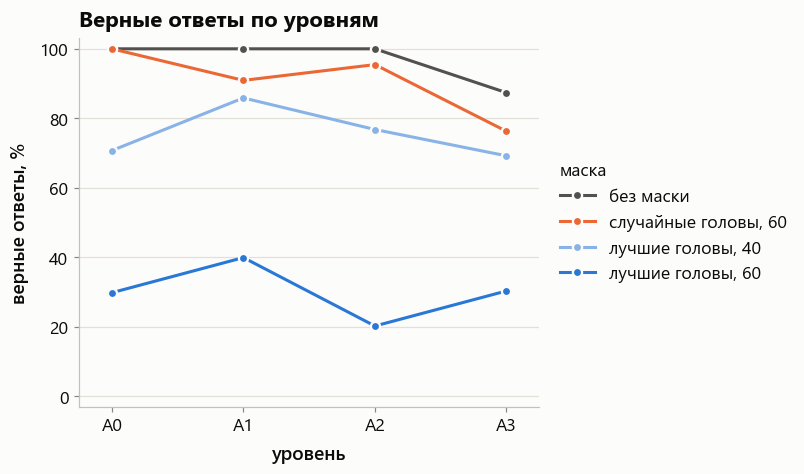

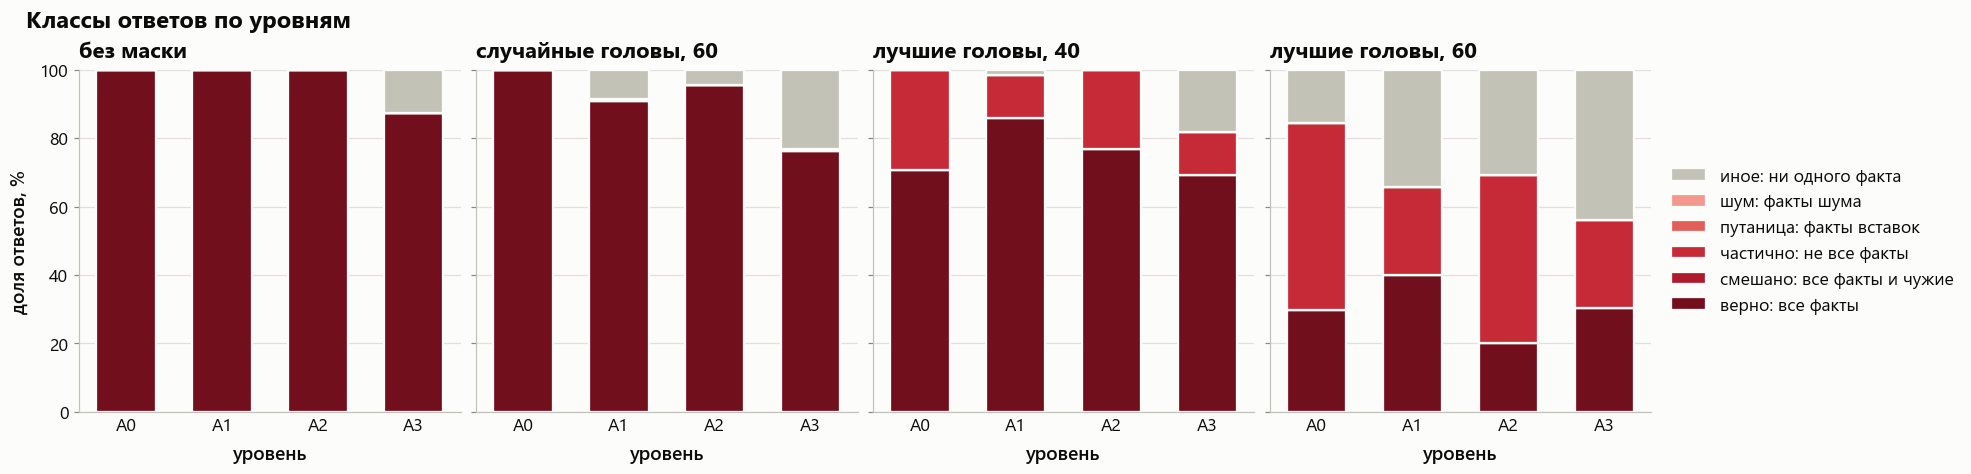

In [6]:
print("верные ответы, %")
display(hard.by_level(sweep))
show(plots.level_lines(sweep, "correct", title="Верные ответы по уровням"), "A_correct_by_level")
show(plots.class_panels(sweep, hard.CLASSES, hard.CLASS_LABELS, title="Классы ответов по уровням"), "A_classes_by_run")

### На тех же примерах

Уровень A3 труднее уже без маски, поэтому доля верных ответов под маской смешивает два эффекта. Здесь берутся только примеры, на которые модель без маски ответила верно, и считается, какая их доля осталась верной под маской. Строка `n` — число таких примеров.

In [7]:
kept = hard.paired(sweep)
display(kept)

base = kept.loc[kept.index != "n", levels[0]]
print(f"разница с {levels[0]}, процентные пункты: плюс — уровень устойчивее к маске, минус — уязвимее")
display(kept.loc[kept.index != "n"].sub(base, axis=0).round(1))

level,A0,A1,A2,A3
n,198.0,198.0,198.0,173.0
random60,100.0,90.9,95.5,86.7
top40,70.7,85.9,76.8,78.6
top60,29.8,39.9,20.2,34.7


разница с A0, процентные пункты: плюс — уровень устойчивее к маске, минус — уязвимее


level,A0,A1,A2,A3
random60,0.0,-9.1,-4.5,-13.3
top40,0.0,15.2,6.1,7.9
top60,0.0,10.1,-9.6,4.9


### По семействам

Шаблоны игл разной сложности: сравнивать уровни нужно внутри семейства и смотреть, совпадает ли направление эффекта.

level               A0     A1     A2     A3
run      family                            
none     cairo   100.0  100.0  100.0  100.0
         lisbon  100.0  100.0  100.0  100.0
         oslo    100.0  100.0  100.0   62.1
random60 cairo   100.0   97.0  100.0   97.0
         lisbon  100.0  100.0  100.0  100.0
         oslo    100.0   75.8   86.4   31.8
top40    cairo    53.0   90.9   69.7   93.9
         lisbon   95.5   95.5   92.4   75.8
         oslo     63.6   71.2   68.2   37.9
top60    cairo    24.2   24.2   19.7   21.2
         lisbon   33.3   72.7   27.3   57.6
         oslo     31.8   22.7   13.6   12.1

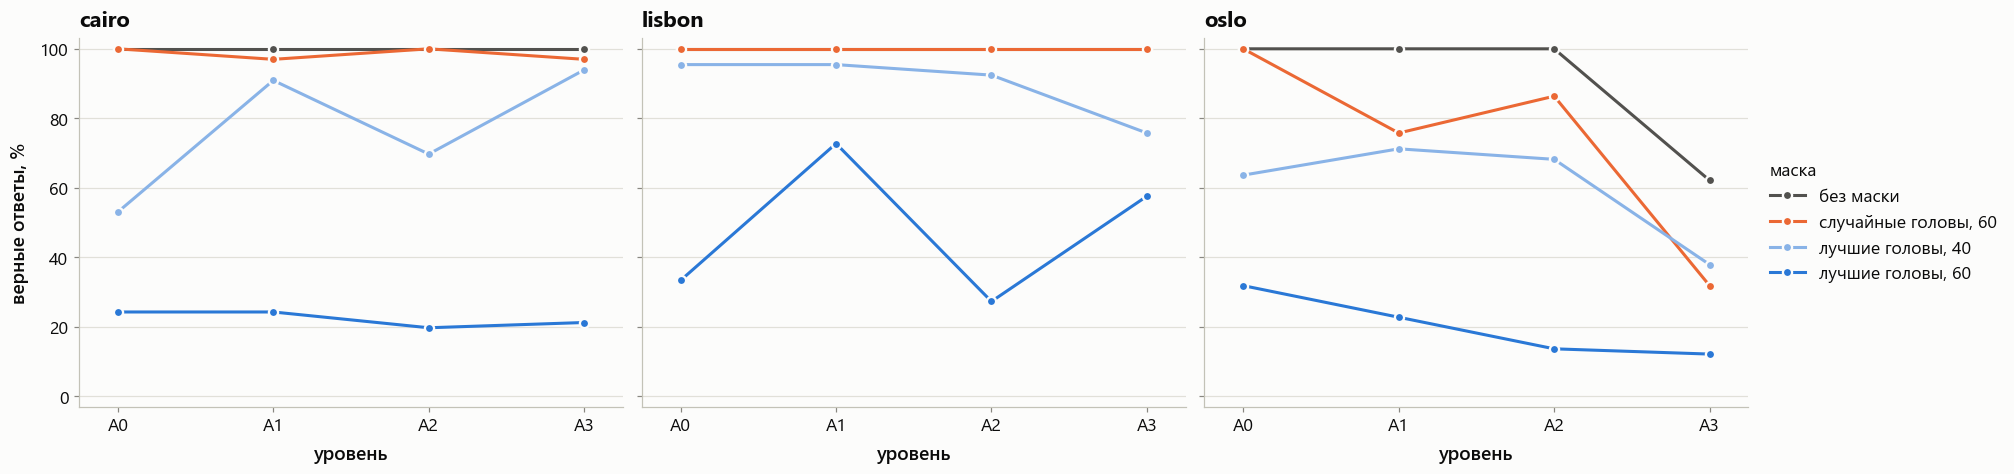

In [8]:
display(hard.by_level(sweep, by=("run", "family", "level")))

axes = panels(len(families), 5.2, extra=2.6, sharey=True)
for ax, family in zip(axes, families):
    plots.level_lines(sweep[sweep["family"] == family], "correct", ax=ax, title=family)
    if ax is not axes[-1]:
        ax.get_legend().remove()
    if ax is not axes[0]:
        ax.set_ylabel("")
show(axes, "A_correct_by_family")

### Вспомогательные метрики и длина ответа

ROUGE здесь не критерий правильности, но показывает, насколько ответ остаётся списанным из иглы.

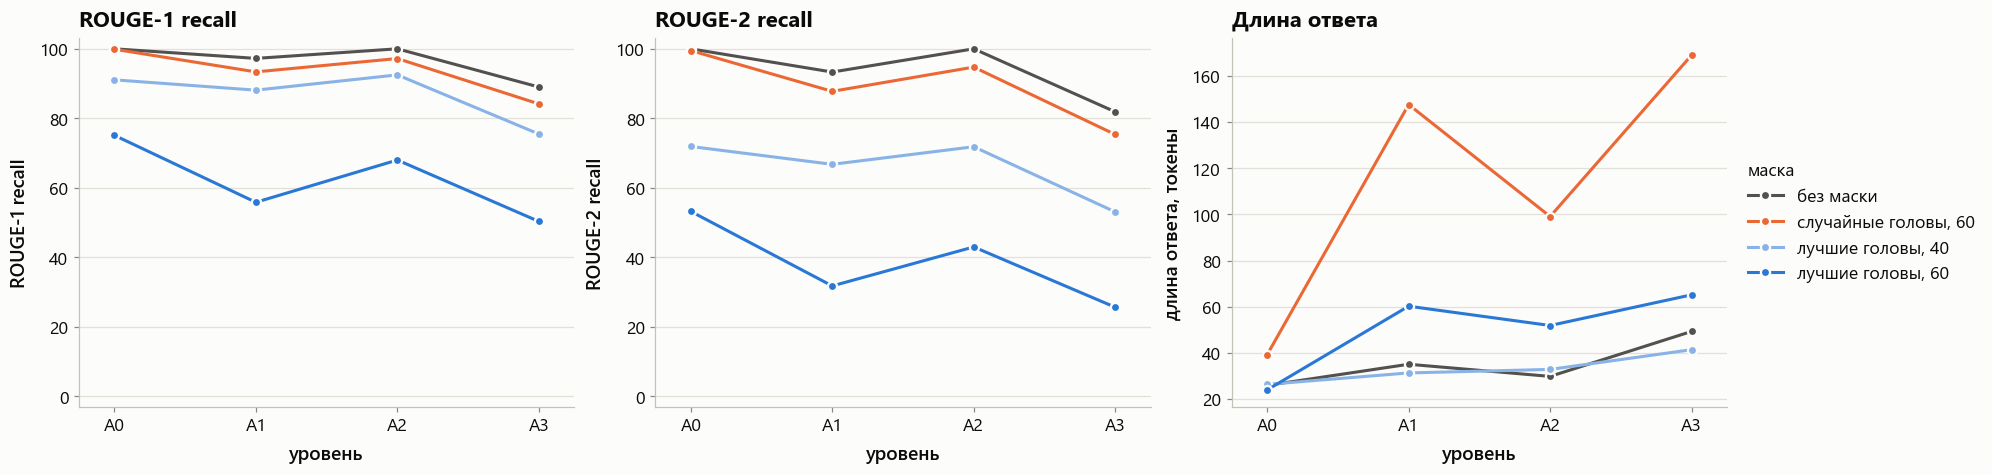

верно  фактов  rouge1  rouge2  rouge3  токенов
run      level                                                
none     A0      1.00    1.00  100.00  100.00  100.00    25.95
         A1      1.00    1.00   97.24   93.31   88.84    35.09
         A2      1.00    1.00  100.00  100.00  100.00    29.83
         A3      0.87    0.87   89.01   81.86   77.73    49.31
random60 A0      1.00    1.00   99.88   99.49   99.31    39.23
         A1      0.91    0.91   93.36   87.75   86.32   147.57
         A2      0.95    0.95   97.20   94.74   93.99    99.07
         A3      0.76    0.77   84.15   75.34   73.60   168.97
top40    A0      0.71    0.85   91.07   71.89   56.09    26.38
         A1      0.86    0.92   88.10   66.74   47.89    31.33
         A2      0.77    0.88   92.50   71.81   56.34    32.86
         A3      0.69    0.76   75.48   53.05   37.48    41.40
top60    A0      0.30    0.57   75.09   53.20   41.32    23.99
         A1      0.40    0.53   55.82   31.74   20.32    60.23
         A2      0.20    0.45   67.99   42.96   32.99    51.87
         A3      0.30    0.43   50.32   25.61   16.61    65.17

In [9]:
axes = panels(3, 6.0)
for ax, (value, name) in zip(axes, {"rouge1_recall": "ROUGE-1 recall", "rouge2_recall": "ROUGE-2 recall", "n_tokens": "Длина ответа"}.items()):
    plots.level_lines(sweep, value, ax=ax, title=name)
    if ax is not axes[-1]:
        ax.get_legend().remove()
show(axes, "A_aux_by_level")

display(sweep.groupby(["run", "level"]).agg(верно=("correct", "mean"), фактов=("facts_found", "mean"), rouge1=("rouge1_recall", "mean"),
                                           rouge2=("rouge2_recall", "mean"), rouge3=("rouge3_recall", "mean"), токенов=("n_tokens", "mean")).round(2))

### Где ломается: длина и глубина

Доля верных ответов по длине контекста и глубине иглы, панель на уровень. В ячейке три примера (по одному на семейство).

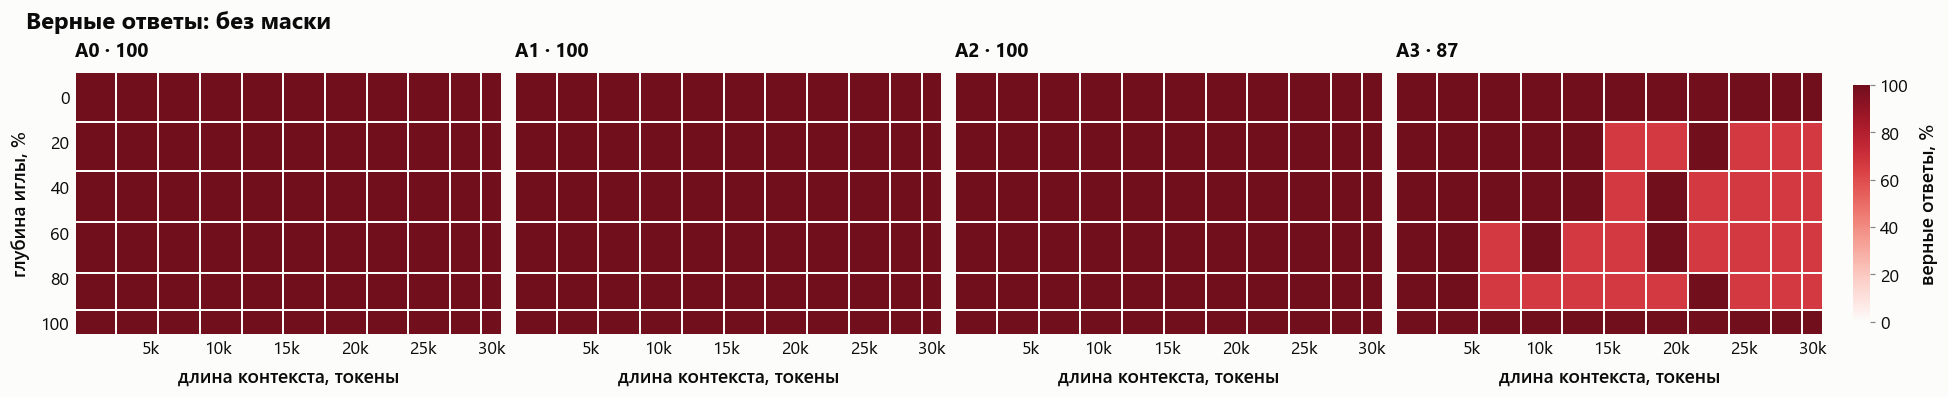

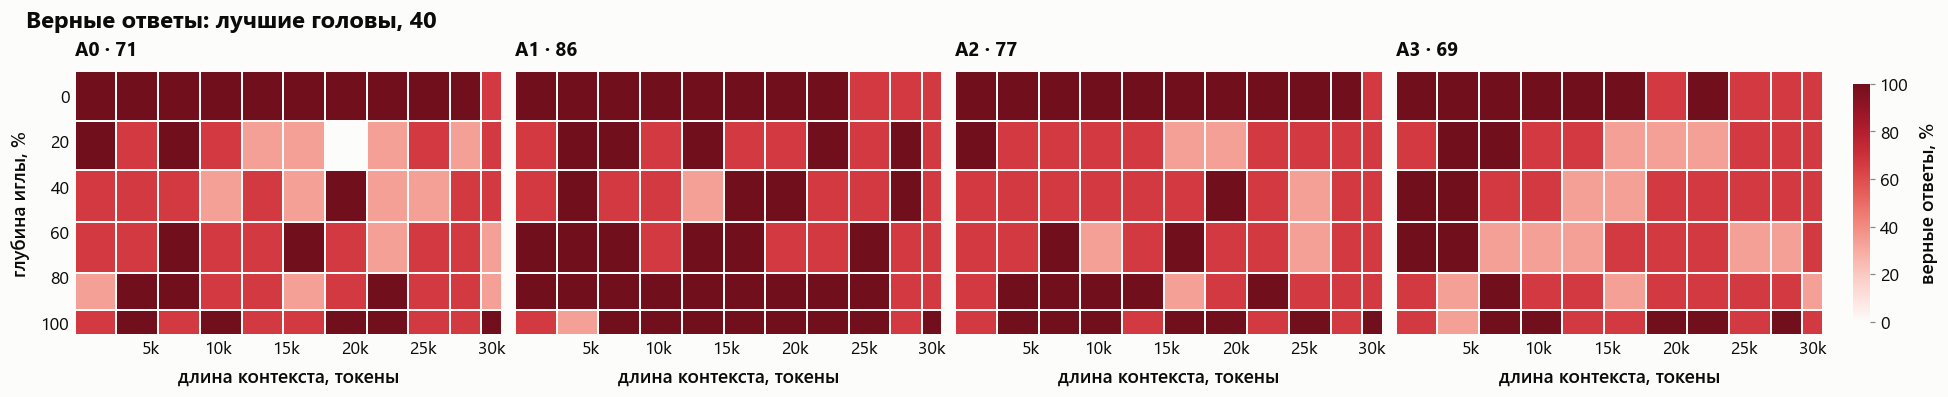

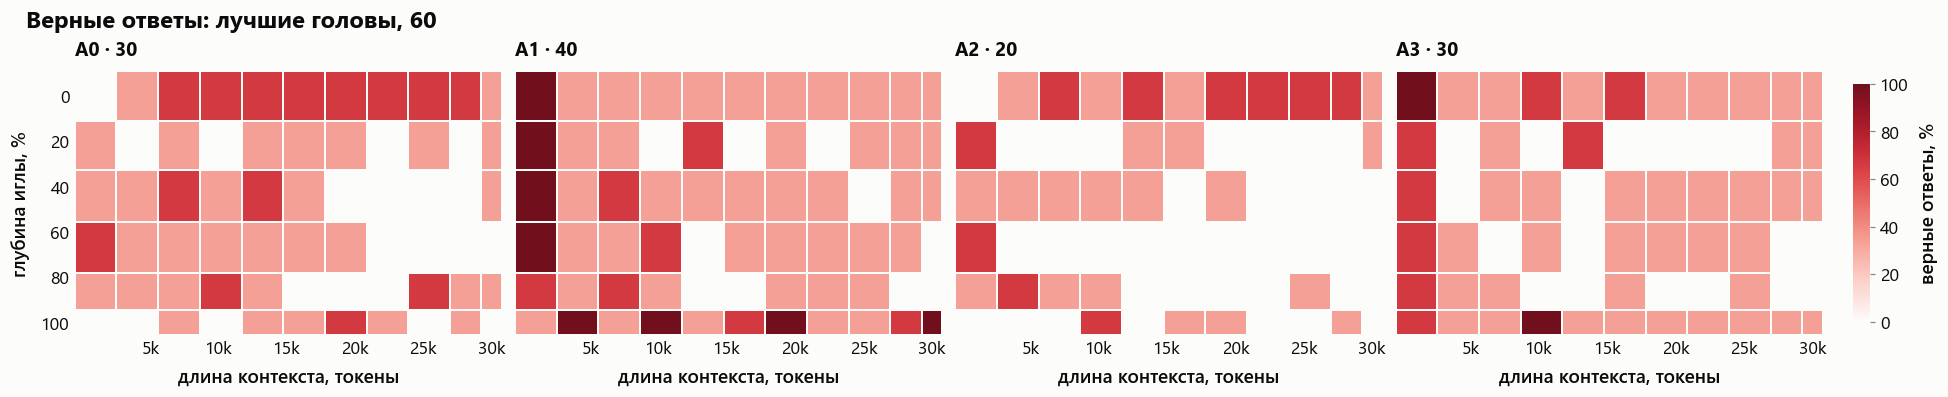

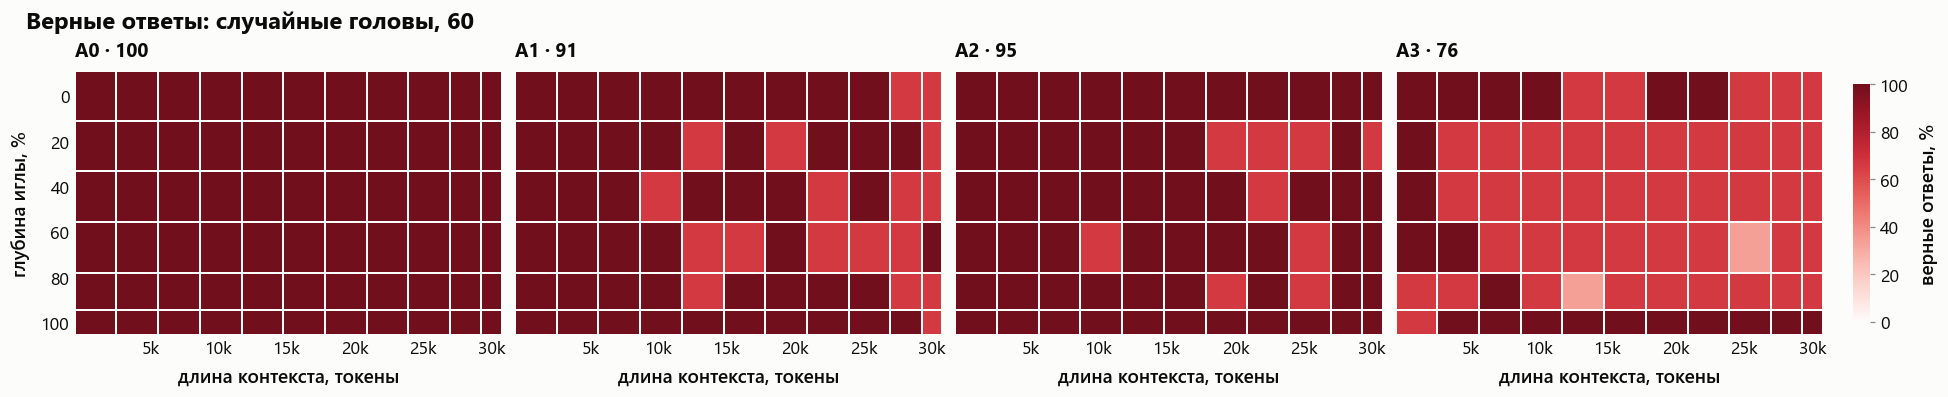

In [10]:
for run in [r for r in ("none", "top40", "top60", "random60") if r in set(sweep["run"])]:
    part = sweep[sweep["run"] == run]
    name = plots.run_styles(sweep)[run][1]
    show(plots.niah_grid(part.assign(run=part["level"]), {level: level for level in levels}, value="correct", columns=4,
                         title=f"Верные ответы: {name}"), f"A_niah_{run}")

### Примеры ответов под маской

По два самых коротких ответа каждого класса на каждом уровне для выбранного прогона.

In [11]:
RUN = "top60"
part = sweep[sweep["run"] == RUN].sort_values("n_tokens").groupby(["level", "answer_class"]).head(2)
part.assign(класс=part["answer_class"].map(hard.CLASS_LABELS)).sort_values(["level", "answer_class"])[["family", "level", "класс", "reference", "response"]]

,family,level,класс,reference,response
2930,oslo,A0,верно: все факты,a roof of red slate and a door painted with a white reindeer,The oldest house in Oslo has a roof of red slate and a door painted with a reindeer.
2907,oslo,A0,верно: все факты,a roof of red slate and a door painted with a white reindeer,The oldest house in Oslo has a roof made of red slate and a door painted with reindeer.
2940,oslo,A0,иное: ни одного факта,a roof of red slate and a door painted with a white reindeer,The oldest house in Oslo has a red roof and a white door.
2928,oslo,A0,иное: ни одного факта,a roof of red slate and a door painted with a white reindeer,The oldest house in Oslo has a red roof and a white door.
2952,oslo,A0,частично: не все факты,a roof of red slate and a door painted with a white reindeer,The oldest house in Oslo has a red roof and a white reindeer painted on it.
2953,oslo,A0,частично: не все факты,a roof of red slate and a door painted with a white reindeer,The oldest house in Oslo has a roof made of red slate and a door painted white.
2447,cairo,A1,верно: все факты,cooked with smoked lemon peel and served in a bowl of black clay,The soup is prepared with smoked lemon peel and served in a bowl made of black clay.
2709,lisbon,A1,верно: все факты,ring the brass bell at the entrance and sign the guest book with a green pen,Guests are requested to ring the brass bell and sign the guest book with a green pen.
2987,oslo,A1,иное: ни одного факта,a roof of red slate and a door painted with a white reindeer,"The most ancient building in Oslo is the oldest house in Oslo, which is the oldest building in Oslo."
2981,oslo,A1,иное: ни одного факта,a roof of red slate and a door painted with a white reindeer,"The most ancient building in Oslo is the Oslo Cathedral, which was constructed in the 12th century."


## 2.3. Те же расчёты без семейства `oslo`

Семейство `oslo` ведёт себя иначе, чем два других: уже без маски на A3 верных ответов 62% (модель отвечает по памяти про Oslo Cathedral), и почти вся потеря под случайной маской приходится на него. Чтобы отделить эффект оси от свойства одной иглы, все расчёты разделов 2.1–2.2 повторены на двух оставшихся семействах: 2 семейства × 4 уровня × 11 длин × 6 глубин = 528 примеров на прогон.

семейства: ['cairo', 'lisbon']; примеров в прогоне: 528
без маски: верные ответы, %


level,A0,A1,A2,A3
family,,,,
cairo,100.0,100.0,100.0,100.0
lisbon,100.0,100.0,100.0,100.0


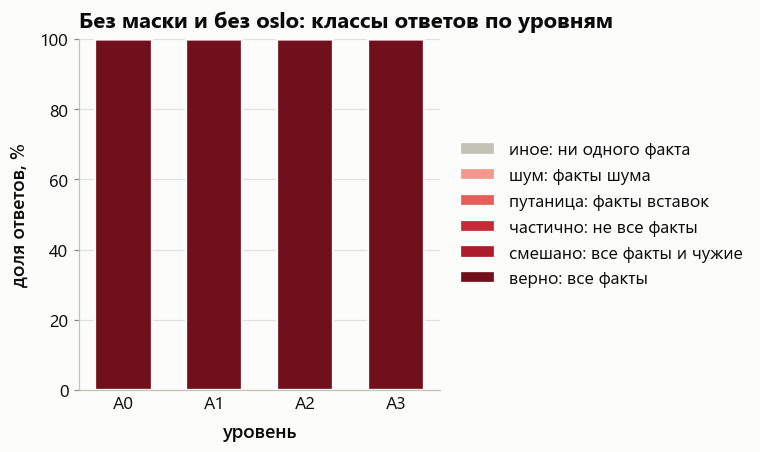

In [12]:
EXCLUDE = ["oslo"]                                        # семейства, которые убираем
rest = sweep[~sweep["family"].isin(EXCLUDE)]
rest_none = rest[rest["run"] == "none"]
print(f"семейства: {sorted(rest['family'].unique())}; примеров в прогоне: {len(rest_none)}")

print("без маски: верные ответы, %")
display(hard.by_level(rest_none, by=("family", "level")))
show(plots.stacked(rest_none, "level", "answer_class", hard.CLASSES, hard.CLASS_LABELS, xlabel="уровень",
                   title="Без маски и без oslo: классы ответов по уровням"), "A_rest_none_classes")

верные ответы, %: без oslo


level,A0,A1,A2,A3
run,,,,
none,100.0,100.0,100.0,100.0
random60,100.0,98.5,100.0,98.5
top40,74.2,93.2,81.1,84.8
top60,28.8,48.5,23.5,39.4


для сравнения — все три семейства


level,A0,A1,A2,A3
run,,,,
none,100.0,100.0,100.0,87.4
random60,100.0,90.9,95.5,76.3
top40,70.7,85.9,76.8,69.2
top60,29.8,39.9,20.2,30.3


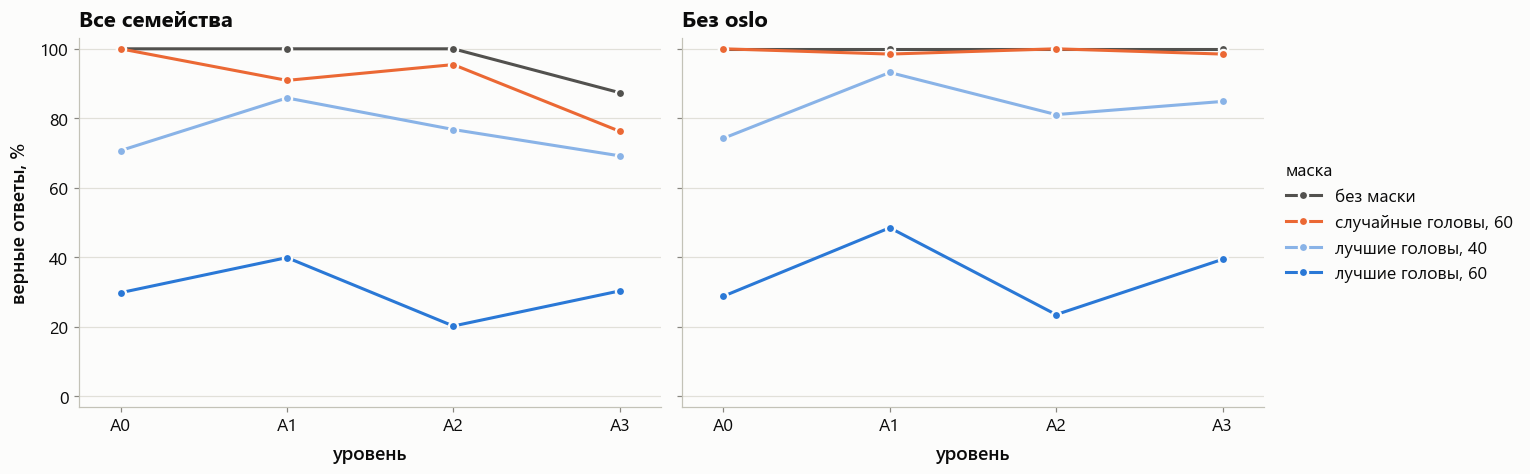

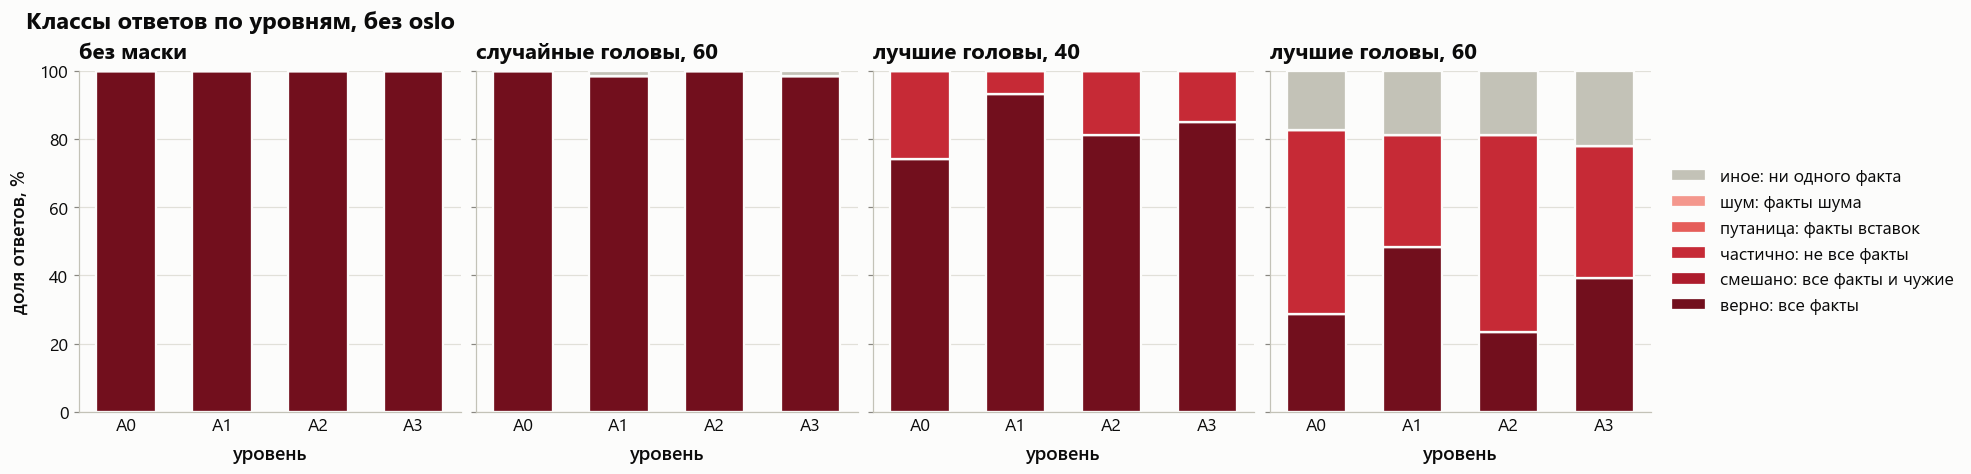

In [13]:
print("верные ответы, %: без oslo")
display(hard.by_level(rest))
print("для сравнения — все три семейства")
display(hard.by_level(sweep))

axes = panels(2, 5.6, extra=2.6, sharey=True)
plots.level_lines(sweep, "correct", ax=axes[0], title="Все семейства")
plots.level_lines(rest, "correct", ax=axes[1], title="Без oslo")
axes[0].get_legend().remove()
axes[1].set_ylabel("")
show(axes, "A_rest_correct_by_level")

show(plots.class_panels(rest, hard.CLASSES, hard.CLASS_LABELS, title="Классы ответов по уровням, без oslo"), "A_rest_classes_by_run")

### На тех же примерах, без `oslo`

Доля примеров, верных без маски, которые остались верными под маской.

In [14]:
kept_rest = hard.paired(rest)
display(kept_rest)

base = kept_rest.loc[kept_rest.index != "n", levels[0]]
print(f"разница с {levels[0]}, процентные пункты: плюс — уровень устойчивее к маске, минус — уязвимее")
display(kept_rest.loc[kept_rest.index != "n"].sub(base, axis=0).round(1))

print("та же разница по всем трём семействам")
display(kept.loc[kept.index != "n"].sub(kept.loc[kept.index != "n", levels[0]], axis=0).round(1))

level,A0,A1,A2,A3
n,132.0,132.0,132.0,132.0
random60,100.0,98.5,100.0,98.5
top40,74.2,93.2,81.1,84.8
top60,28.8,48.5,23.5,39.4


разница с A0, процентные пункты: плюс — уровень устойчивее к маске, минус — уязвимее


level,A0,A1,A2,A3
random60,0.0,-1.5,0.0,-1.5
top40,0.0,19.0,6.9,10.6
top60,0.0,19.7,-5.3,10.6


та же разница по всем трём семействам


level,A0,A1,A2,A3
random60,0.0,-9.1,-4.5,-13.3
top40,0.0,15.2,6.1,7.9
top60,0.0,10.1,-9.6,4.9


### Вспомогательные метрики и длина ответа, без `oslo`

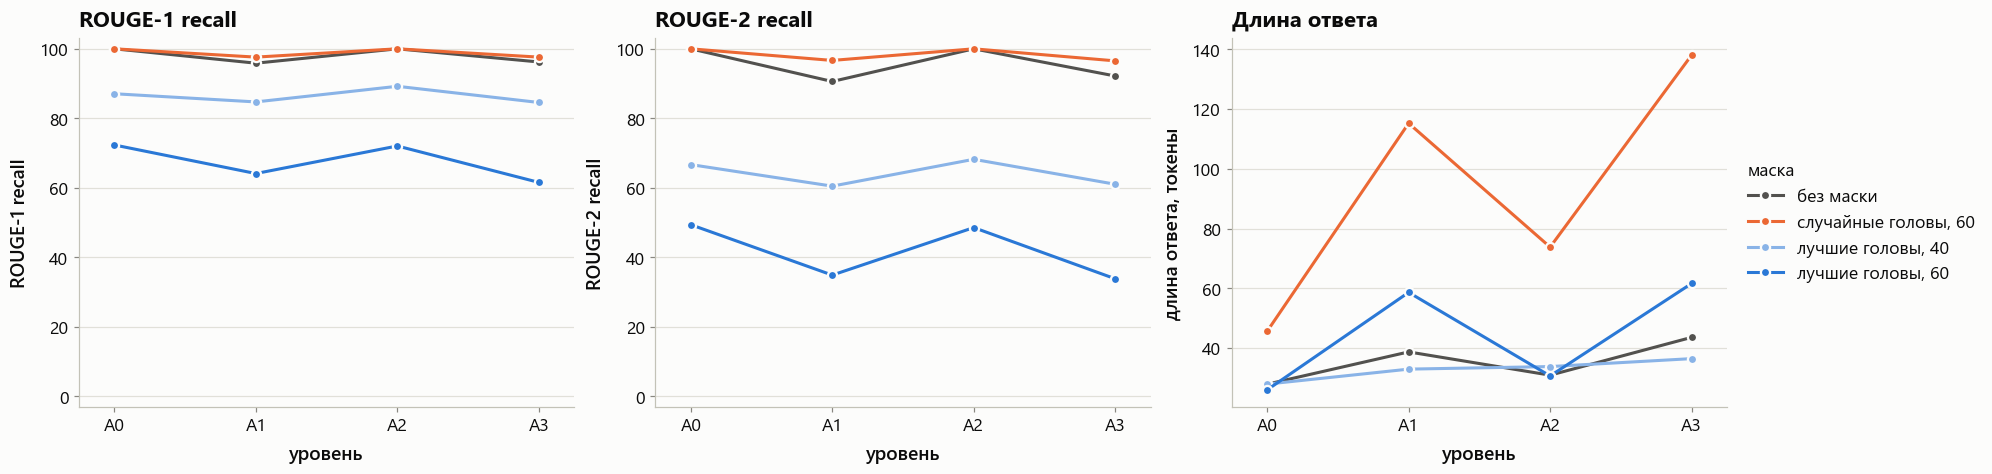

верно  фактов  rouge1  rouge2  rouge3  токенов
run      level                                                
none     A0      1.00    1.00  100.00  100.00  100.00    27.91
         A1      1.00    1.00   95.86   90.59   84.64    38.71
         A2      1.00    1.00  100.00  100.00  100.00    30.92
         A3      1.00    1.00   96.21   92.17   87.47    43.58
random60 A0      1.00    1.00  100.00  100.00  100.00    45.63
         A1      0.98    0.98   97.61   96.65   96.35   115.27
         A2      1.00    1.00  100.00  100.00  100.00    73.81
         A3      0.98    0.98   97.61   96.53   96.21   138.09
top40    A0      0.74    0.87   87.07   66.67   49.29    27.93
         A1      0.93    0.97   84.71   60.47   37.74    32.95
         A2      0.81    0.91   89.21   68.19   52.14    33.80
         A3      0.85    0.92   84.55   61.01   40.99    36.46
top60    A0      0.29    0.56   72.32   49.37   38.08    26.00
         A1      0.48    0.65   64.10   34.86   19.95    58.64
         A2      0.23    0.52   72.03   48.54   37.77    30.67
         A3      0.39    0.59   61.55   33.80   20.93    61.62

In [15]:
axes = panels(3, 6.0)
for ax, (value, name) in zip(axes, {"rouge1_recall": "ROUGE-1 recall", "rouge2_recall": "ROUGE-2 recall", "n_tokens": "Длина ответа"}.items()):
    plots.level_lines(rest, value, ax=ax, title=name)
    if ax is not axes[-1]:
        ax.get_legend().remove()
show(axes, "A_rest_aux_by_level")

display(rest.groupby(["run", "level"]).agg(верно=("correct", "mean"), фактов=("facts_found", "mean"), rouge1=("rouge1_recall", "mean"),
                                          rouge2=("rouge2_recall", "mean"), rouge3=("rouge3_recall", "mean"), токенов=("n_tokens", "mean")).round(2))

### Где ломается: длина и глубина, без `oslo`

В ячейке два примера (по одному на семейство).

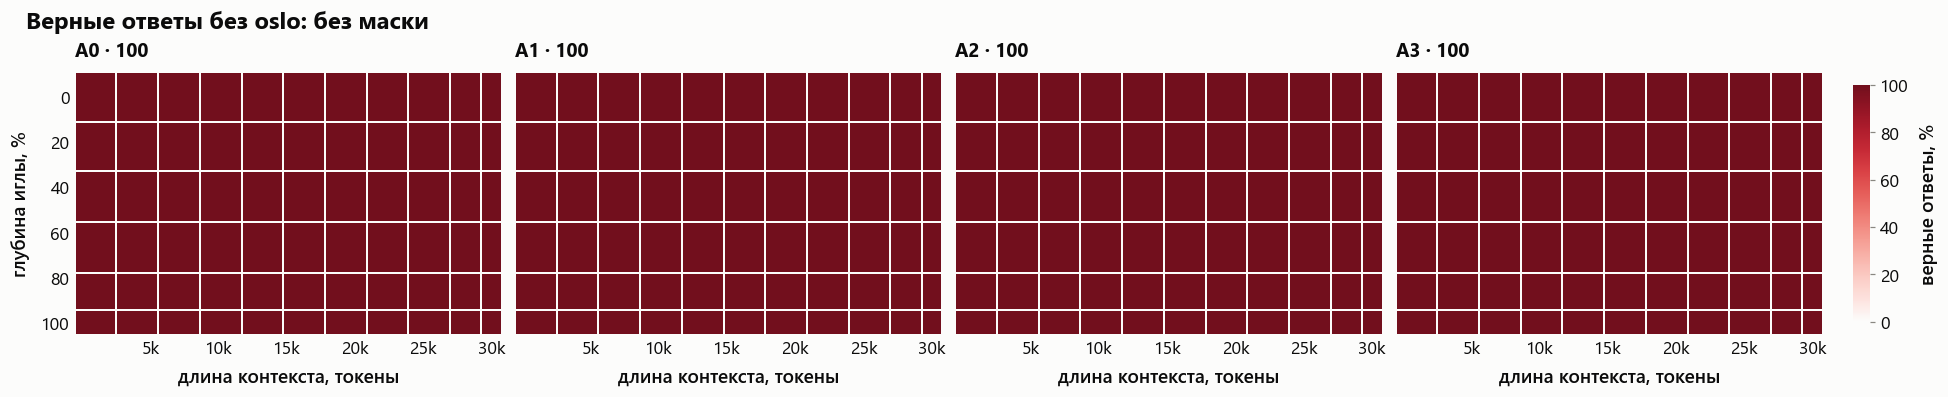

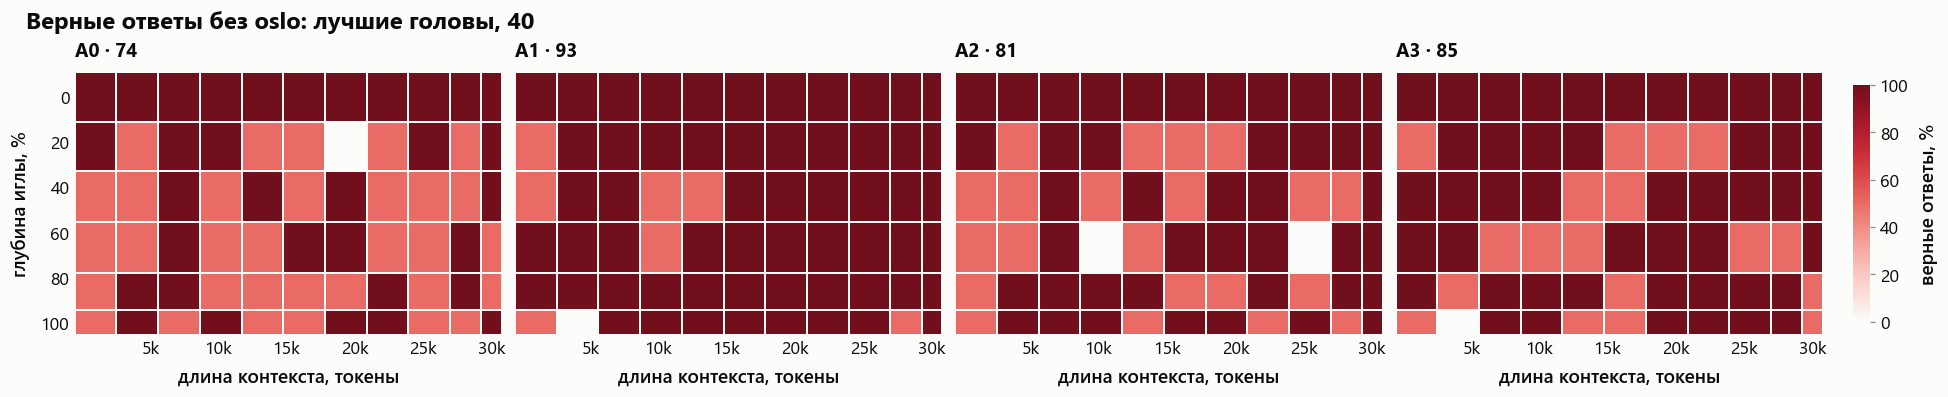

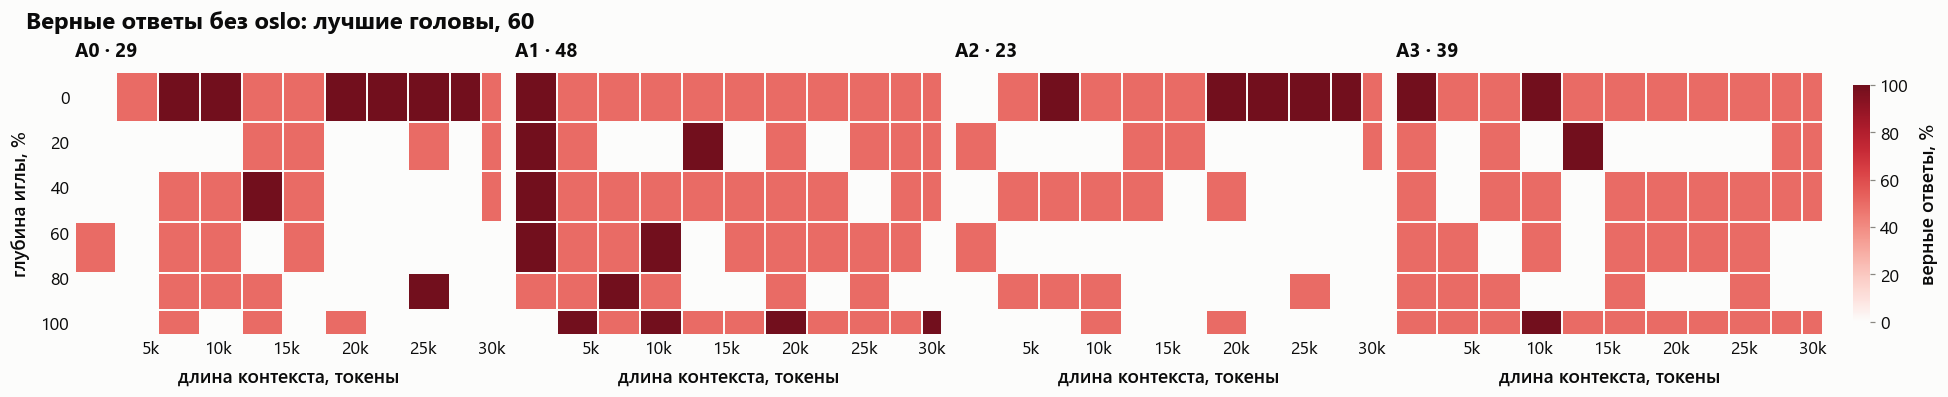

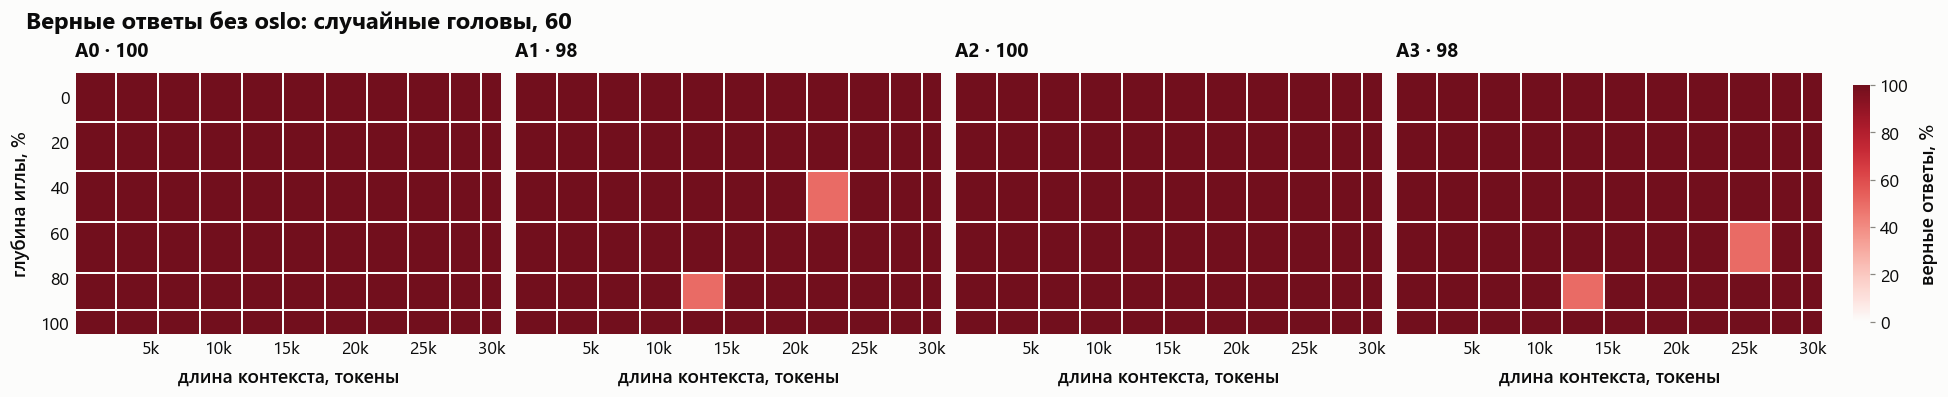

In [16]:
for run in [r for r in ("none", "top40", "top60", "random60") if r in set(rest["run"])]:
    part = rest[rest["run"] == run]
    name = plots.run_styles(rest)[run][1]
    show(plots.niah_grid(part.assign(run=part["level"]), {level: level for level in levels}, value="correct", columns=4,
                         title=f"Верные ответы без oslo: {name}"), f"A_rest_niah_{run}")

## 2.4. Формулировки ответов: перефраз, замены, формы слов

Класс по фактам говорит, названы ли ключевые факты. Здесь тот же ответ разбирается подробнее: эталон разбит на части, и для каждой части смотрим, как она записана — дословно, другой формой тех же слов, близкой заменой или никак. Это тот же разбор, что в ноутбуке по задаче статьи, с теми же уровнями и структурами.

| Уровень формулировки | Что это | Пример |
|---|---|---|
| дословно | формулировка эталона | `cooked with` |
| другая форма слова | те же слова в другой форме, с другим артиклем или в другом порядке | `cooking it with`; `a brass bell`; `black clay bowl` |
| синоним, смысл сохранён | другие слова с тем же смыслом | `prepared using`; `when they arrive` вместо `at the entrance` |
| потеряна деталь | часть названа, но без существенной детали | `ring a bell` без `brass`; `smoked lemon` без `peel`; `red roof` без `slate` |
| нет | части в ответе нет | — |

Часть считается сохранённой на первых трёх уровнях. Списки формулировок лежат в `vizual/paraphrase.py` (`FACTS`) и собраны вручную по ответам этих прогонов: это перечень того, что модель действительно писала, а не словарь синонимов. Отнесение формулировки к уровню — моё решение, оно видно в таблице ниже.

| Структура ответа | Условие |
|---|---|
| точная фраза | эталон стоит в ответе дословно и подряд |
| все части дословно, другой порядок или вставка | все части дословно, но фраза не совпадает |
| все части, есть форма слова или синоним | все части сохранены, хотя бы одна не дословно — **перефразированный полный ответ** |
| не все части, остальные дословно | часть пропала, оставшиеся дословно — обрезанный ответ |
| не все части, есть форма, синоним или потеря детали | часть пропала или потеряла деталь |
| ни одной части | ответ не из иглы |

In [17]:
from vizual import paraphrase

worded = paraphrase.annotate(sweep)
worded_none = worded[worded["run"] == "none"]
fact_names = {family: list(paraphrase.FACTS[worded.loc[worded["family"] == family, "reference"].iloc[0]]) for family in families}

# что именно написано вместо формулировки эталона: по всем прогонам
pd.set_option("display.max_rows", 200)
paraphrase.wordings(worded, top=5).set_index(["эталон", "факт", "уровень"])

написано  \
эталон                                                                       факт                  уровень                                                      
ring the brass bell at the entrance and sign the guest book with a green pen ring the brass bell   другая форма слова                       ring a brass bell   
                                                                                                   другая форма слова                    ringing a brass bell   
                                                                                                   другая форма слова                  ringing the brass bell   
                                                                                                   другая форма слова                    ringe the brass bell   
                                                                                                   потеряна деталь                                ring a bell   
                                                                                                   потеряна деталь                              ring the bell   
                                                                                                   потеряна деталь                             rings the bell   
                                                                             at the entrance       синоним, смысл сохранён                   when they arrive   
                                                                                                   синоним, смысл сохранён                        arriving at   
                                                                                                   синоним, смысл сохранён                 when guests arrive   
                                                                                                   синоним, смысл сохранён                       upon arrival   
                                                                                                   синоним, смысл сохранён                           entering   
                                                                             sign the guest book   другая форма слова                       sign a guest book   
                                                                                                   другая форма слова                        sign a guestbook   
                                                                                                   другая форма слова                      sign the guestbook   
                                                                                                   другая форма слова                  signing the guest book   
                                                                                                   другая форма слова                    signing a guest book   
                                                                                                   синоним, смысл сохранён    sign their name in a guest book   
                                                                                                   синоним, смысл сохранён   sign their names in a guest book   
                                                                                                   синоним, смысл сохранён    sign their names in a guestbook   
                                                                                                   синоним, смысл сохранён     sign their name in a guestbook   
                                                                                                   синоним, смысл сохранён  sign their name in the guest book   
                                                                                                   потеряна деталь                                 guest book   
                                                                                                   потеряна деталь          

### Без маски: как модель формулирует ответ на каждом уровне

Перефраз вопроса (A1, A3) меняет формулировку ответа и без вмешательства в модель.

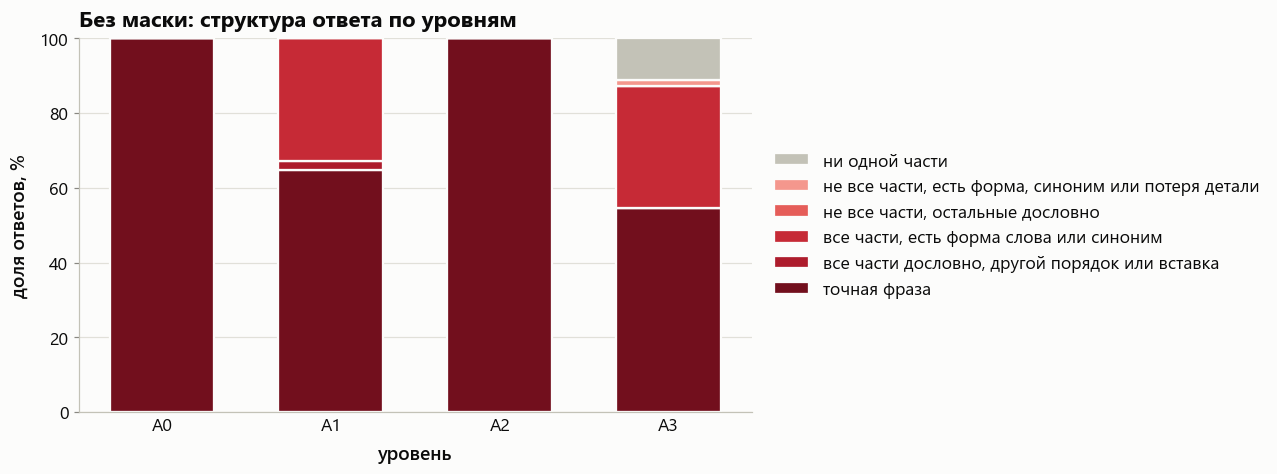

без маски: доля ответов каждой структуры, %


structure     точная фраза  все части дословно, другой порядок или вставка  \
family level                                                                 
cairo  A0            100.0                                             0.0   
       A1              9.1                                             7.6   
       A2            100.0                                             0.0   
       A3             22.7                                             0.0   
lisbon A0            100.0                                             0.0   
       A1            100.0                                             0.0   
       A2            100.0                                             0.0   
       A3            100.0                                             0.0   
oslo   A0            100.0                                             0.0   
       A1             84.8                                             0.0   
       A2            100.0                                             0.0   
       A3             40.9                                             0.0   

structure     все части, есть форма слова или синоним  \
family level                                            
cairo  A0                                         0.0   
       A1                                        83.3   
       A2                                         0.0   
       A3                                        77.3   
lisbon A0                                         0.0   
       A1                                         0.0   
       A2                                         0.0   
       A3                                         0.0   
oslo   A0                                         0.0   
       A1                                        15.2   
       A2                                         0.0   
       A3                                        21.2   

structure     не все части, есть форма, синоним или потеря детали  \
family level                                                        
cairo  A0                                                     0.0   
       A1                                                     0.0   
       A2                                                     0.0   
       A3                                                     0.0   
lisbon A0                                                     0.0   
       A1                                                     0.0   
       A2                                                     0.0   
       A3                                                     0.0   
oslo   A0                                                     0.0   
       A1                                                     0.0   
       A2                                                     0.0   
       A3                                                     4.5   

structure     ни одной части  
family level                  
cairo  A0                0.0  
       A1                0.0  
       A2                0.0  
       A3                0.0  
lisbon A0                0.0  
       A1                0.0  
       A2                0.0  
       A3                0.0  
oslo   A0                0.0  
       A1                0.0  
       A2                0.0  
       A3               33.3

In [18]:
ax = plt.subplots(figsize=style.size(11.5, 4.2))[1]
show(plots.stacked(worded_none, "level", "structure", paraphrase.STRUCTURES, paraphrase.STRUCTURE_LABELS, xlabel="уровень", ax=ax,
                   title="Без маски: структура ответа по уровням"), "A_structure_none")

print("без маски: доля ответов каждой структуры, %")
display((pd.crosstab([worded_none["family"], worded_none["level"]], worded_none["structure"], normalize="index") * 100).reindex(
    columns=[k for k in paraphrase.STRUCTURES if k in set(worded_none["structure"])]).rename(columns=paraphrase.STRUCTURE_LABELS).round(1))

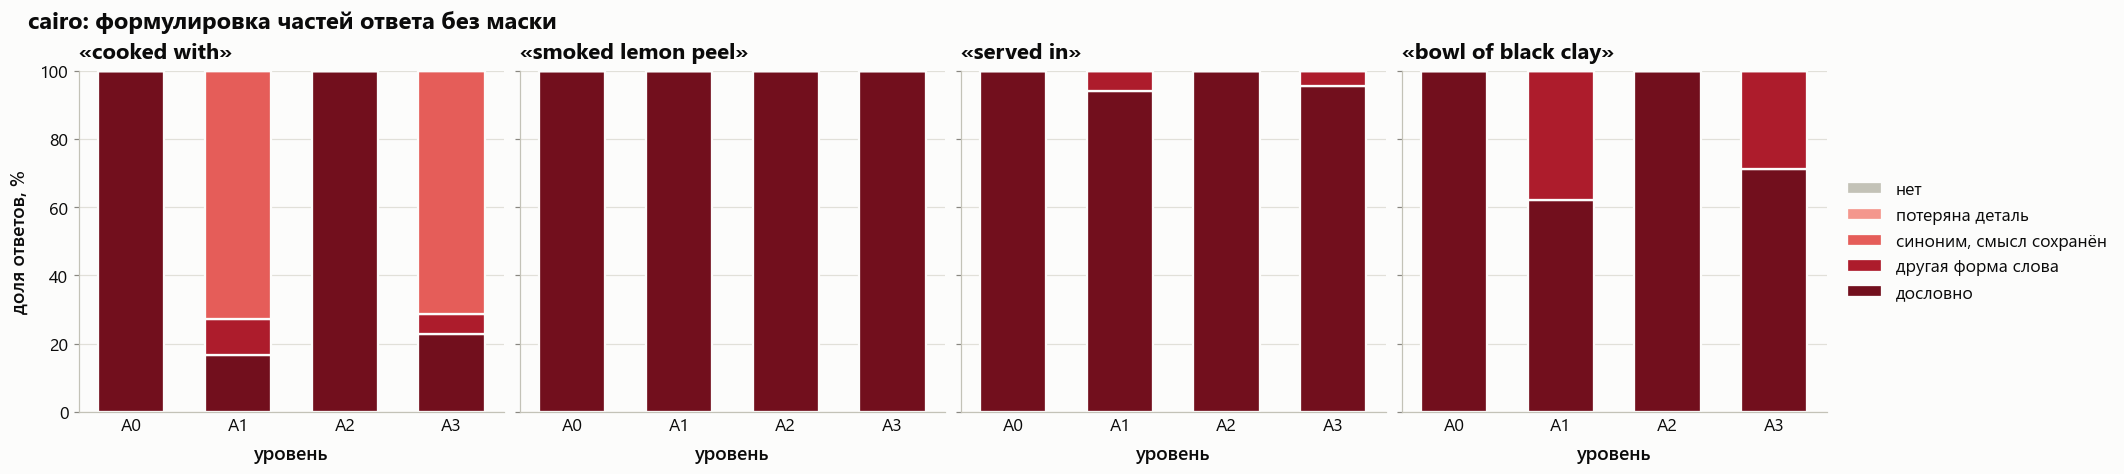

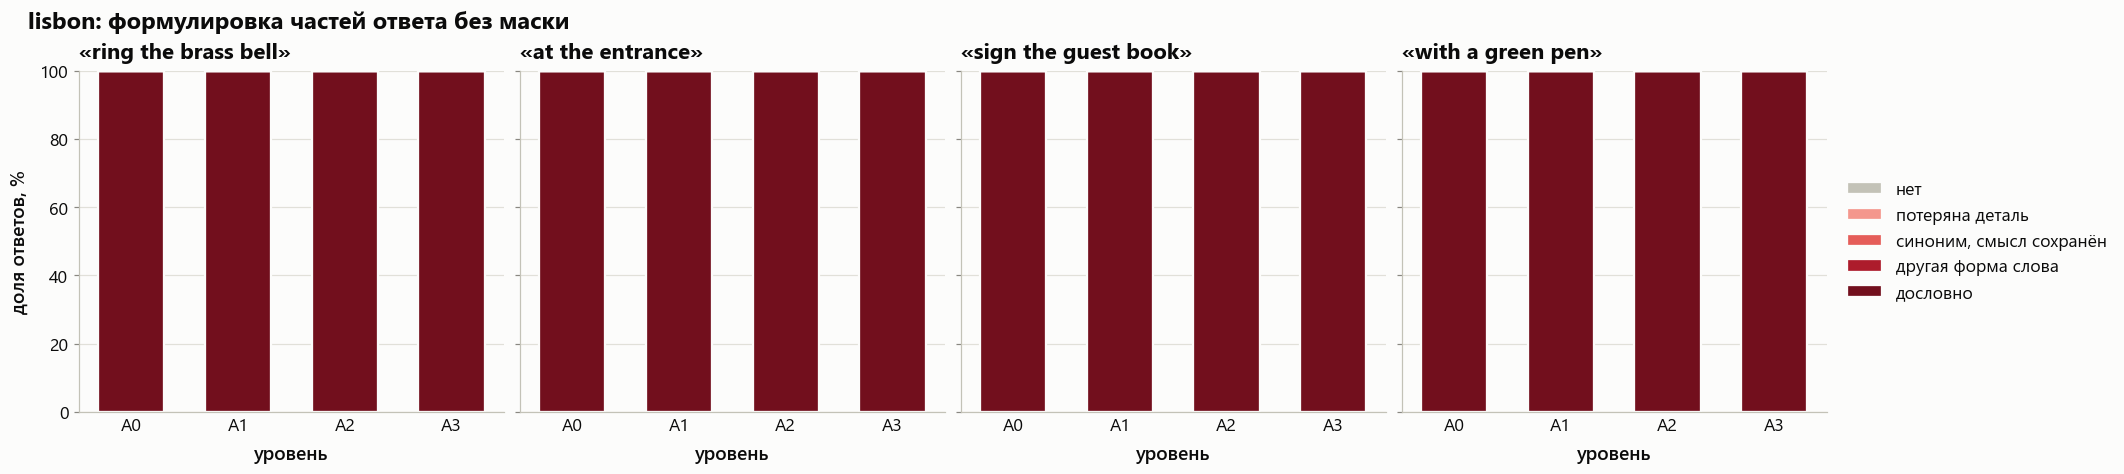

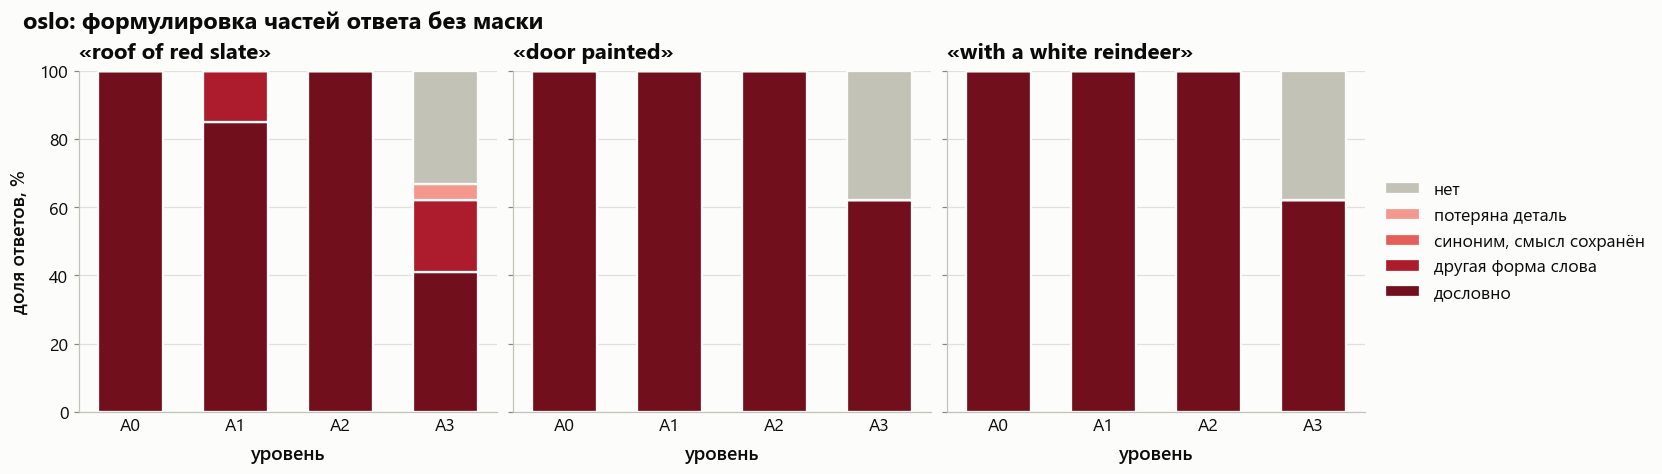

In [19]:
# как записана каждая часть эталона, без маски: панель на часть, ряд на семейство
for family in families:
    part = worded_none[worded_none["family"] == family]
    names = fact_names[family]
    axes = panels(len(names), 4.2, extra=2.4, sharey=True)
    for ax, fact in zip(axes, names):
        plots.stacked(part, "level", fact, paraphrase.LEVELS, paraphrase.LEVEL_LABELS, xlabel="уровень", legend=ax is axes[-1], ax=ax, title=f"«{fact}»")
        if ax is not axes[0]:
            ax.set_ylabel("")
    axes[0].figure.suptitle(f"{family}: формулировка частей ответа без маски", x=0.01, ha="left", fontweight="bold")
    show(axes, f"A_fact_wordings_{family}")

### Как строковые метрики и класс по фактам оценивают каждую структуру

По всем прогонам оси. `верно` — доля ответов класса «верно» по фактам; `частей` — сколько частей эталона сохранено (дословно, формой слова или синонимом; у `oslo` частей три, у остальных четыре).

Разбор по частям строже класса по фактам: класс требует двух ключевых фактов, а здесь проверяется весь эталон. Поэтому ответ без `at the entrance` или `with a green pen` верен по фактам, но относится к «не все части».

In [20]:
by_structure = worded.groupby("structure").agg(ответов=("id", "size"), частей=("kept_facts", "mean"), верно=("correct", "mean"), точная_фраза=("exact", "mean"),
                                               rouge1=("rouge1_recall", "mean"), rouge2=("rouge2_recall", "mean"), rouge3=("rouge3_recall", "mean"),
                                               успех1=("success", "mean"), успех2=("success2", "mean"), успех3=("success3", "mean")).reindex(paraphrase.STRUCTURES)
by_structure[["верно", "точная_фраза", "успех1", "успех2", "успех3"]] *= 100
display(by_structure.round(1).rename(index=paraphrase.STRUCTURE_LABELS))

print("структура против класса по фактам, число ответов")
display(pd.crosstab(worded["structure"], worded["answer_class"]).reindex(paraphrase.STRUCTURES).rename(index=paraphrase.STRUCTURE_LABELS, columns=hard.CLASS_LABELS))

,ответов,частей,верно,точная_фраза,rouge1,rouge2,rouge3,успех1,успех2,успех3
structure,,,,,,,,,,
точная фраза,1267,3.7,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0
"все части дословно, другой порядок или вставка",16,3.9,100.0,0.0,100.0,94.5,89.1,100.0,100.0,100.0
"все части, есть форма слова или синоним",684,3.7,94.7,0.0,93.5,79.6,66.1,100.0,96.1,74.1
"не все части, остальные дословно",80,2.8,91.2,0.0,81.7,67.8,58.2,97.5,82.5,80.0
"не все части, есть форма, синоним или потеря детали",876,2.0,36.3,0.0,73.4,44.9,29.3,85.8,47.8,20.1
ни одной части,245,0.0,0.0,0.0,23.1,0.8,0.0,0.4,0.0,0.0


структура против класса по фактам, число ответов


answer_class,верно: все факты,иное: ни одного факта,частично: не все факты
structure,,,
точная фраза,1267,0,0
"все части дословно, другой порядок или вставка",16,0,0
"все части, есть форма слова или синоним",648,0,36
"не все части, остальные дословно",73,0,7
"не все части, есть форма, синоним или потеря детали",318,138,420
ни одной части,0,245,0


### Под масками

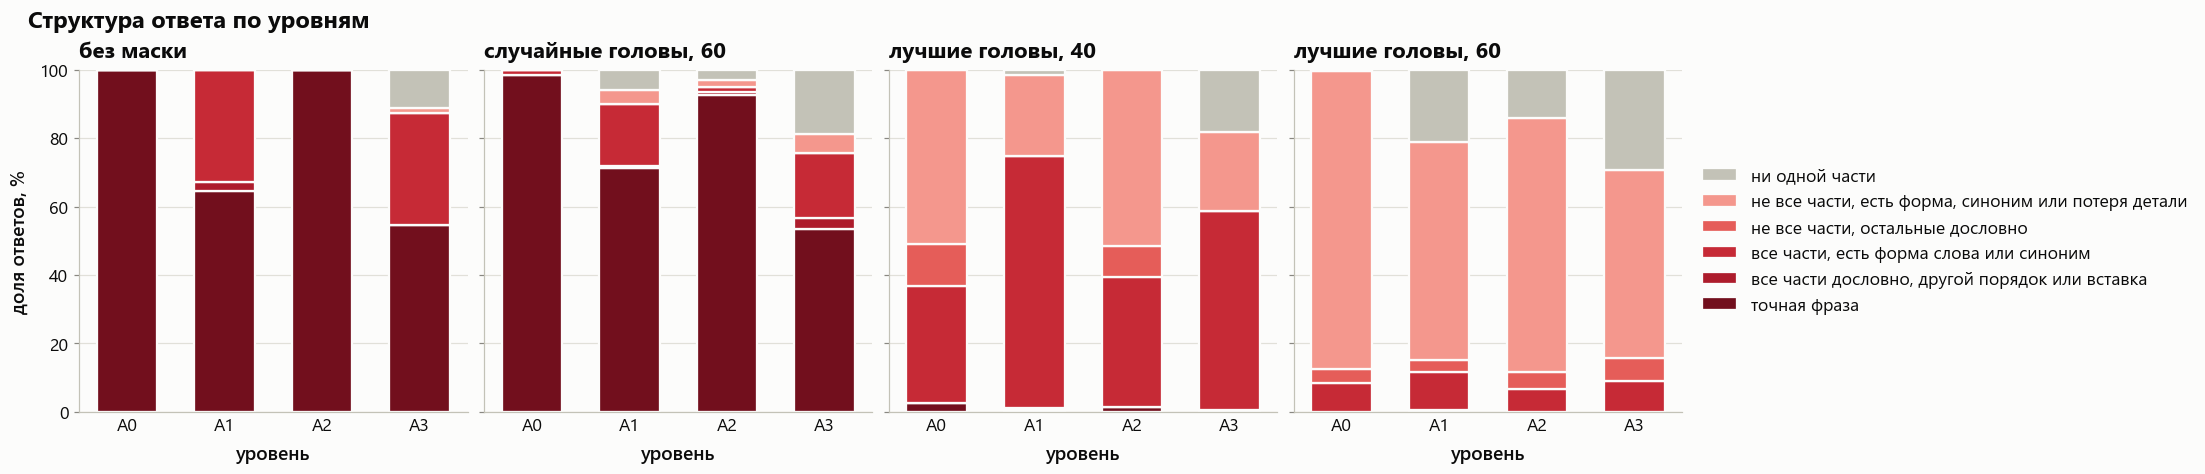

ответы со всеми частями эталона (дословно, формой слова или синонимом), %


level,A0,A1,A2,A3
run,,,,
none,100.0,100.0,100.0,87.4
random60,100.0,89.9,94.9,75.8
top40,36.9,74.7,39.4,58.6
top60,8.6,11.6,6.6,9.1


из них перефразированные (не точная фраза), %


level,A0,A1,A2,A3
run,,,,
none,0.0,35.4,0.0,37.6
random60,1.5,20.8,2.7,29.3
top40,93.2,99.3,96.2,100.0
top60,100.0,95.7,100.0,100.0


In [21]:
show(plots.class_panels(worded, paraphrase.STRUCTURES, paraphrase.STRUCTURE_LABELS, column="structure", title="Структура ответа по уровням"), "A_structure_by_run")

full = worded["structure"].isin(["exact", "reordered", "reworded"])
print("ответы со всеми частями эталона (дословно, формой слова или синонимом), %")
display(hard.by_level(worded.assign(full=full), "full"))
print("из них перефразированные (не точная фраза), %")
display(hard.by_level(worded[full].assign(reworded=lambda d: d["structure"] != "exact"), "reworded"))

In [22]:
# примеры: по два самых коротких ответа каждой структуры
examples = worded[~worded["exact"]].sort_values("n_tokens").groupby("structure").head(2)
examples.assign(структура=examples["structure"].map(paraphrase.STRUCTURE_LABELS)).set_index("структура").loc[
    [paraphrase.STRUCTURE_LABELS[k] for k in paraphrase.STRUCTURES if k in set(examples["structure"])],
    ["run", "family", "level", "answer_class", "rouge1_recall", "response"]].round(0)

,run,family,level,answer_class,rouge1_recall,response
структура,,,,,,
"все части дословно, другой порядок или вставка",random60,cairo,A3,correct,100.0,"The well-known soup at the Zahira Cafe in Egypt's capital, Cairo, is prepared with smoked lemon peel and served in a bowl of black clay. The soup is cooked with smoked lemon peel and served in a black clay bowl."
"все части дословно, другой порядок или вставка",random60,cairo,A3,correct,100.0,"The well-known soup at the Zahira Cafe in Egypt's capital, Cairo, is prepared with smoked lemon peel and served in a bowl of black clay. The soup is cooked with smoked lemon peel and served in a black clay bowl."
"все части, есть форма слова или синоним",top60,cairo,A3,correct,92.0,The soup is prepared with smoked lemon peel and served in a bowl made of black clay.
"все части, есть форма слова или синоним",top40,cairo,A3,correct,92.0,The soup is prepared with smoked lemon peel and served in a bowl made of black clay.
"не все части, остальные дословно",top60,lisbon,A3,correct,81.0,Ring the brass bell and sign the guest book with a green pen.
"не все части, остальные дословно",top60,lisbon,A3,correct,56.0,Every guest is requested to ring the brass bell and sign the guest book.
"не все части, есть форма, синоним или потеря детали",top60,lisbon,A3,partial,50.0,Rings the bell and signs the guest book.
"не все части, есть форма, синоним или потеря детали",top60,lisbon,A1,partial,44.0,Guests are requested to ring a bell and sign a guest book.
ни одной части,top60,oslo,A1,other,0.0,"The most ancient building in Oslo is the oldest house in Oslo, which is the oldest building in Oslo."


## 2.5. Формулировки ответов без семейства `oslo`

Тот же разбор, что в разделе 2.4, на семействах `cairo` и `lisbon`. У `oslo` на A3 треть ответов без маски — не из иглы, и это смешивается с изменением формулировки; здесь остаются только семейства, у которых без маски все ответы верны.

семейства: ['cairo', 'lisbon']; примеров в прогоне: 528


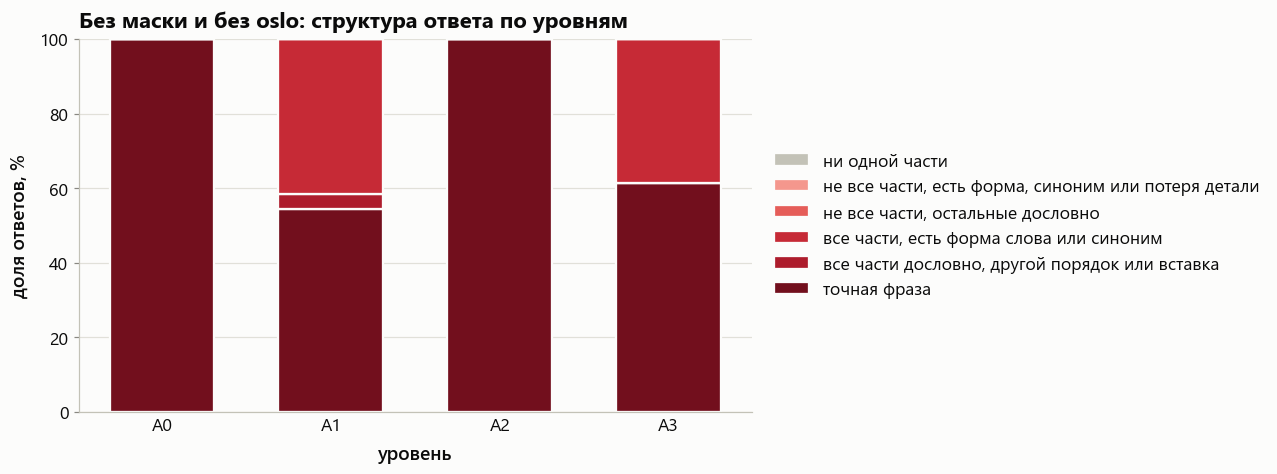

без маски: доля ответов каждой структуры, %


structure     точная фраза  все части дословно, другой порядок или вставка  \
family level                                                                 
cairo  A0            100.0                                             0.0   
       A1              9.1                                             7.6   
       A2            100.0                                             0.0   
       A3             22.7                                             0.0   
lisbon A0            100.0                                             0.0   
       A1            100.0                                             0.0   
       A2            100.0                                             0.0   
       A3            100.0                                             0.0   

structure     все части, есть форма слова или синоним  
family level                                           
cairo  A0                                         0.0  
       A1                                        83.3  
       A2                                         0.0  
       A3                                        77.3  
lisbon A0                                         0.0  
       A1                                         0.0  
       A2                                         0.0  
       A3                                         0.0

In [23]:
worded_rest = worded[~worded["family"].isin(EXCLUDE)]
worded_rest_none = worded_rest[worded_rest["run"] == "none"]
print(f"семейства: {sorted(worded_rest['family'].unique())}; примеров в прогоне: {len(worded_rest_none)}")

ax = plt.subplots(figsize=style.size(11.5, 4.2))[1]
show(plots.stacked(worded_rest_none, "level", "structure", paraphrase.STRUCTURES, paraphrase.STRUCTURE_LABELS, xlabel="уровень", ax=ax,
                   title="Без маски и без oslo: структура ответа по уровням"), "A_rest_structure_none")

print("без маски: доля ответов каждой структуры, %")
display((pd.crosstab([worded_rest_none["family"], worded_rest_none["level"]], worded_rest_none["structure"], normalize="index") * 100).reindex(
    columns=[k for k in paraphrase.STRUCTURES if k in set(worded_rest_none["structure"])]).rename(columns=paraphrase.STRUCTURE_LABELS).round(1))

### Как метрики оценивают каждую структуру, без `oslo`

In [24]:
by_structure_rest = worded_rest.groupby("structure").agg(ответов=("id", "size"), частей=("kept_facts", "mean"), верно=("correct", "mean"), точная_фраза=("exact", "mean"),
                                                         rouge1=("rouge1_recall", "mean"), rouge2=("rouge2_recall", "mean"), rouge3=("rouge3_recall", "mean"),
                                                         успех1=("success", "mean"), успех2=("success2", "mean"), успех3=("success3", "mean")).reindex(paraphrase.STRUCTURES)
by_structure_rest[["верно", "точная_фраза", "успех1", "успех2", "успех3"]] *= 100
display(by_structure_rest.round(1).rename(index=paraphrase.STRUCTURE_LABELS))

print("структура против класса по фактам, число ответов")
display(pd.crosstab(worded_rest["structure"], worded_rest["answer_class"]).reindex(paraphrase.STRUCTURES).rename(index=paraphrase.STRUCTURE_LABELS, columns=hard.CLASS_LABELS))

,ответов,частей,верно,точная_фраза,rouge1,rouge2,rouge3,успех1,успех2,успех3
structure,,,,,,,,,,
точная фраза,875,4.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0
"все части дословно, другой порядок или вставка",14,4.0,100.0,0.0,100.0,96.7,92.1,100.0,100.0,100.0
"все части, есть форма слова или синоним",512,4.0,98.8,0.0,91.4,76.7,62.0,100.0,94.9,65.6
"не все части, остальные дословно",79,2.8,92.4,0.0,81.7,67.8,58.2,97.5,82.3,79.7
"не все части, есть форма, синоним или потеря детали",631,2.2,33.1,0.0,68.1,39.2,23.7,80.8,34.5,17.4
ни одной части,1,0.0,0.0,0.0,30.8,0.0,0.0,0.0,0.0,0.0


структура против класса по фактам, число ответов


answer_class,верно: все факты,иное: ни одного факта,частично: не все факты
structure,,,
точная фраза,875,0,0
"все части дословно, другой порядок или вставка",14,0,0
"все части, есть форма слова или синоним",506,0,6
"не все части, остальные дословно",73,0,6
"не все части, есть форма, синоним или потеря детали",209,105,317
ни одной части,0,1,0


### Под масками, без `oslo`

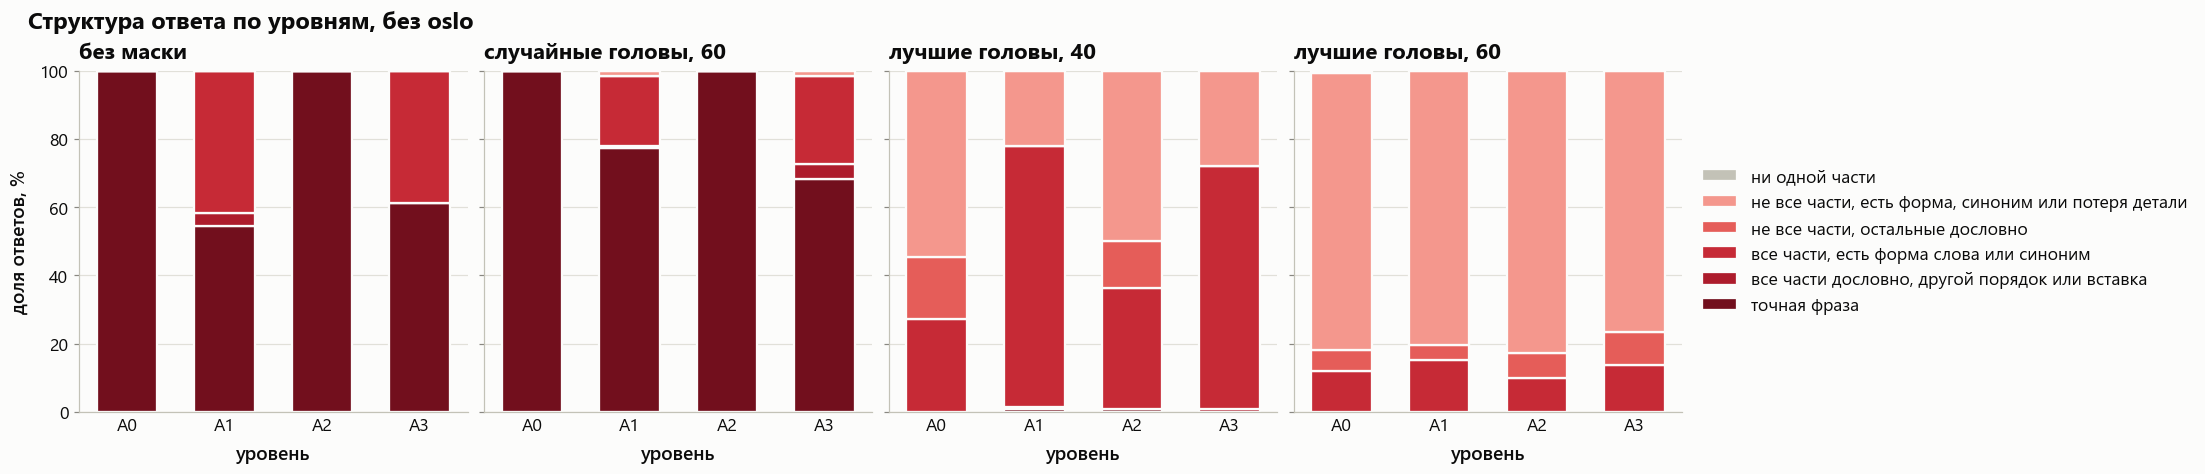

ответы со всеми частями эталона (дословно, формой слова или синонимом), %: без oslo


level,A0,A1,A2,A3
run,,,,
none,100.0,100.0,100.0,100.0
random60,100.0,98.5,100.0,98.5
top40,27.3,78.0,36.4,72.0
top60,12.1,15.2,9.8,13.6


то же по всем трём семействам


level,A0,A1,A2,A3
run,,,,
none,100.0,100.0,100.0,87.4
random60,100.0,89.9,94.9,75.8
top40,36.9,74.7,39.4,58.6
top60,8.6,11.6,6.6,9.1


из полных ответов перефразированные (не точная фраза), %: без oslo


level,A0,A1,A2,A3
run,,,,
none,0.0,45.5,0.0,38.6
random60,0.0,21.5,0.0,30.8
top40,100.0,99.0,97.9,100.0
top60,100.0,100.0,100.0,100.0


In [25]:
show(plots.class_panels(worded_rest, paraphrase.STRUCTURES, paraphrase.STRUCTURE_LABELS, column="structure", title="Структура ответа по уровням, без oslo"), "A_rest_structure_by_run")

full_rest = worded_rest["structure"].isin(["exact", "reordered", "reworded"])
print("ответы со всеми частями эталона (дословно, формой слова или синонимом), %: без oslo")
display(hard.by_level(worded_rest.assign(full=full_rest), "full"))
print("то же по всем трём семействам")
display(hard.by_level(worded.assign(full=full), "full"))
print("из полных ответов перефразированные (не точная фраза), %: без oslo")
display(hard.by_level(worded_rest[full_rest].assign(reworded=lambda d: d["structure"] != "exact"), "reworded"))

# 3. Метрики голов

Только прогон без маски. Скоры считаются по верно отвеченным примерам.

| Метрика | Годится? | Почему |
|---|---|---|
| `copy_recall`, `copy_count` — скор копирования из статьи | да, с контролем | игла не менялась, ответ по-прежнему списывается из неё; но скор зависит от того, насколько дословно модель отвечает (раздел 3.4) |
| частота активации | да | доля примеров, где голова скопировала хотя бы один токен иглы |
| `needle_mass` — масса внимания на ответе в игле | да | не требует дословного ответа: меряет, куда голова смотрит, а не что копирует |
| `needle_sentence_mass` — масса на всей игле | да | то же для всего предложения иглы, включая ключ («Lisbon Tram Museum»), который на A2 и A3 в вопросе не назван |
| `needle_attention_mass` | да | масса на ответе на тех шагах, где модель выдаёт токен из ответа |
| `competing_mass`, `competing_max_mass`, `copy_competing`, `supporting_mass` | нет | это внимание на вставки, а на оси A вставок нет: значения тождественно равны нулю |
| `copy_sentence` | дублирует `copy_count` | копирование из всей иглы; отличается только токенами вне ответа |

In [26]:
heads = data.Heads(NONE, samples=none, ok="correct")      # в скор входят верные ответы
detect = data.Heads(DETECT)                               # детекция на простой задаче (условие — успех по ROUGE-1, как в статье)
reference = detect.score(METRIC)                          # скор детекции, [слой, голова]
order = np.argsort(-reference.ravel(), kind="stable")     # головы от лучшей к худшей по детекции
total_heads = reference.size

common = hard.common_cells(heads.samples)                 # места иглы, отвеченные верно на всех уровнях
print(f"примеров с метриками голов: {len(heads.samples)}; на местах, верных на всех уровнях: {common.sum()} ({common.sum() // len(levels)} на уровень)")

scores = hard.level_scores(heads, METRIC, where=common)                                              # {уровень: [слой, голова]}
rankings = {level: heads.ranking(METRIC, hard.level_mask(heads, level, common)) for level in levels}   # рейтинг голов самого уровня

примеров с метриками голов: 792; на местах, верных на всех уровнях: 692 (173 на уровень)


## 3.1. Те же графики, что на исходной задаче

Каждый график из ноутбука по задаче статьи, построенный отдельно для каждого уровня. Здесь рейтинг считается заново на самом уровне — чтобы увидеть, как выглядела бы детекция, проведённая на перефразированном вопросе.

### Распределение голов по скору (рис. 3 статьи)

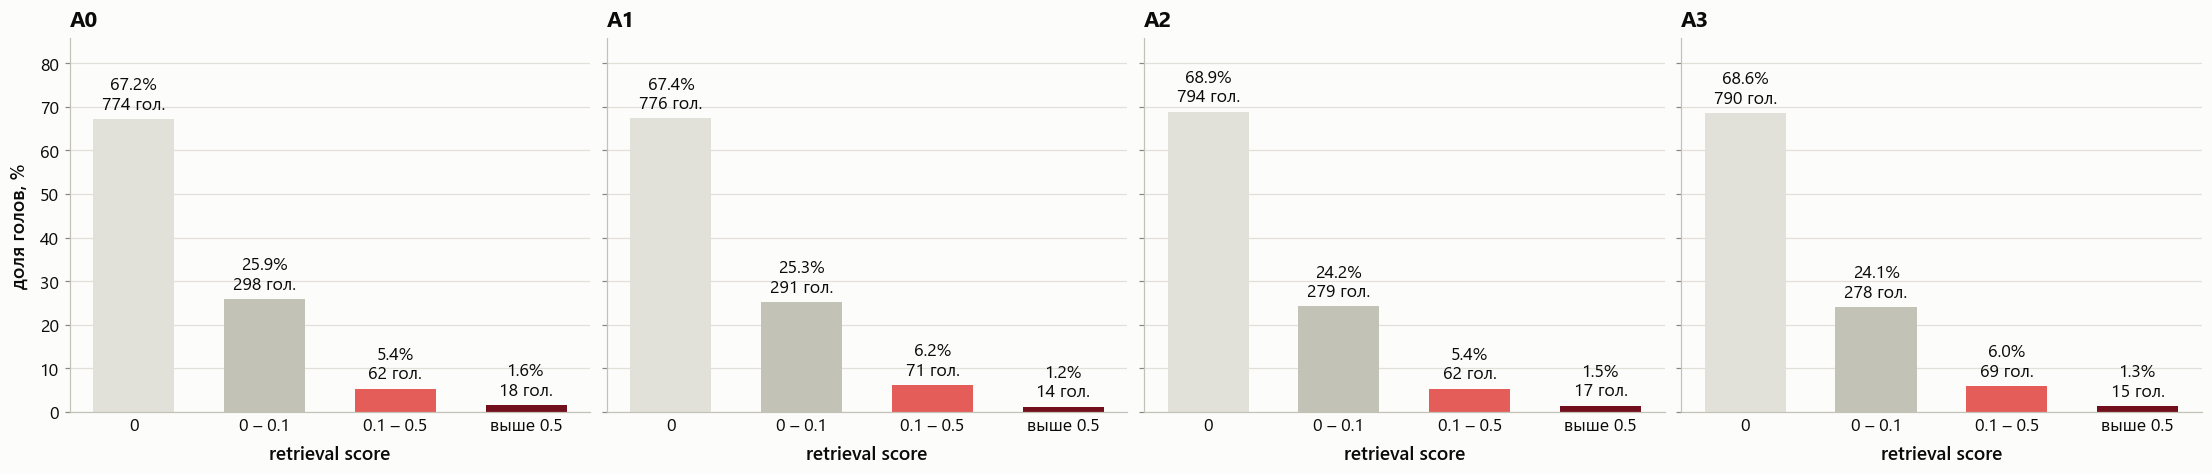

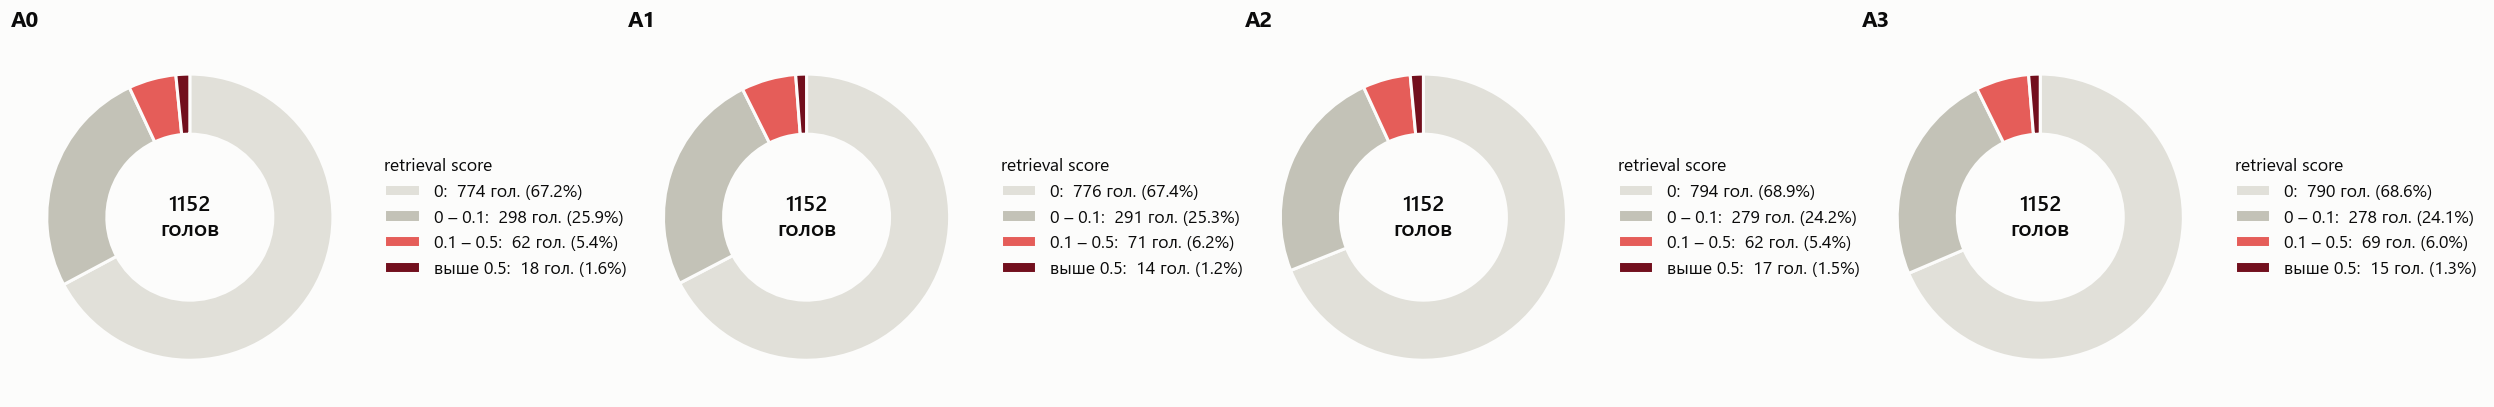

доля голов, %


,ровно 0,0 – 0.1,0.1 – 0.5,выше 0.5,голов выше 0.1
детекция,57.9,36.7,4.2,1.2,62.0
A0,67.2,25.9,5.4,1.6,80.0
A1,67.4,25.3,6.2,1.2,85.0
A2,68.9,24.2,5.4,1.5,79.0
A3,68.6,24.1,6.0,1.3,84.0


In [27]:
axes = panels(len(levels), 5.0, sharey=True)
for ax, level in zip(axes, levels):
    plots.score_distribution(scores[level], ax=ax, title=level)
    if ax is not axes[0]:
        ax.set_ylabel("")
show(axes, "A_score_distribution")

axes = panels(len(levels), 5.6, 3.6)
for ax, level in zip(axes, levels):
    plots.score_pie(scores[level], ax=ax, title=level)
show(axes, "A_score_pie")

share = lambda s: {"ровно 0": (s == 0).mean() * 100, "0 – 0.1": ((s > 0) & (s <= 0.1)).mean() * 100, "0.1 – 0.5": ((s > 0.1) & (s <= 0.5)).mean() * 100,
                   "выше 0.5": (s > 0.5).mean() * 100, f"голов выше {THRESHOLD}": float((s > THRESHOLD).sum())}
print("доля голов, %")
display(pd.DataFrame({"детекция": share(reference), **{level: share(scores[level]) for level in levels}}).T.round(1))

### Скор и частота активации (рис. 4 статьи)

Головы упорядочены по скору самого уровня. Частота активации — доля примеров уровня, в которых голова скопировала хотя бы один токен иглы.

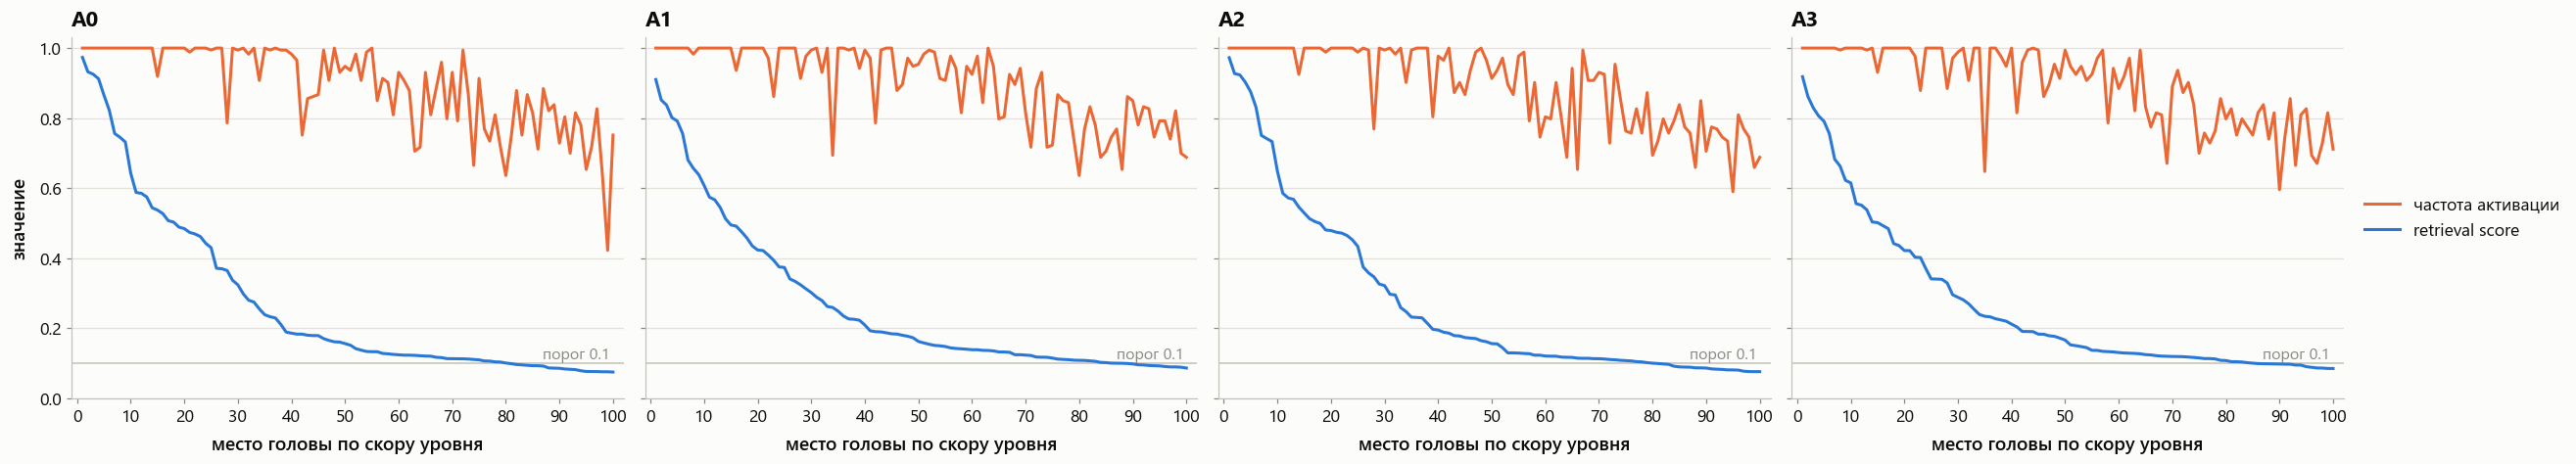

голов, активных во всех примерах уровня: {'A0': 31, 'A1': 31, 'A2': 31, 'A3': 29}


In [28]:
axes = panels(len(levels), 5.4, extra=2.2, sharey=True)
for ax, level in zip(axes, levels):
    plots.score_vs_frequency(rankings[level], top=100, threshold=THRESHOLD, ax=ax, title=level)
    ax.set_xlabel("место головы по скору уровня")
    if ax is not axes[-1]:
        ax.get_legend().remove()
    if ax is not axes[0]:
        ax.set_ylabel("")
show(axes, "A_score_vs_frequency")

print("голов, активных во всех примерах уровня:", {level: int((rankings[level]["frequency"] == 1).sum()) for level in levels})

### Скор каждой головы (рис. 5 статьи)

Одна шкала цвета на всех панелях.

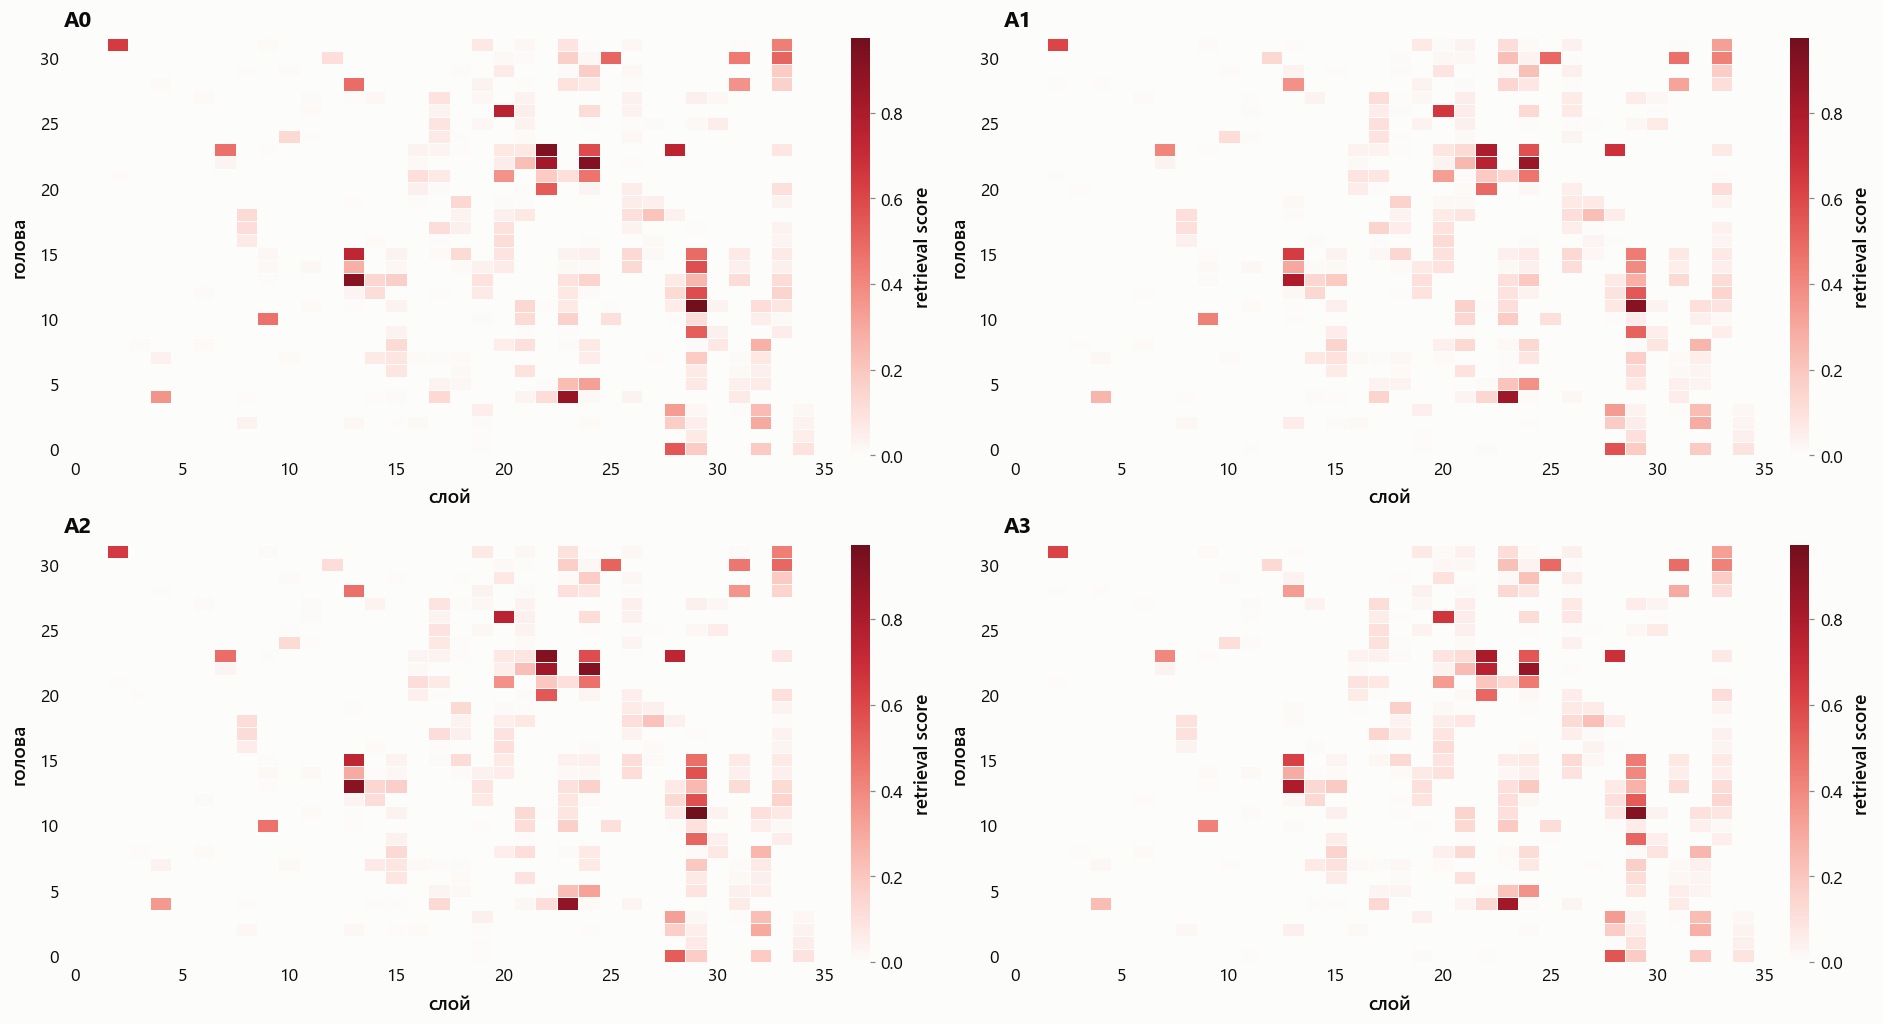

In [29]:
vmax = max(float(s.max()) for s in scores.values())
fig, axes = plt.subplots(2, 2, figsize=style.size(17, 9.2))
for ax, level in zip(axes.ravel(), levels):
    plots.head_heatmap(scores[level], heads.layers, vmax=vmax, ax=ax, title=level)
show(axes, "A_head_heatmap")

### 20 лучших голов уровня

Рейтинг самого уровня. Сравнение с рейтингом детекции — в разделе 3.2.

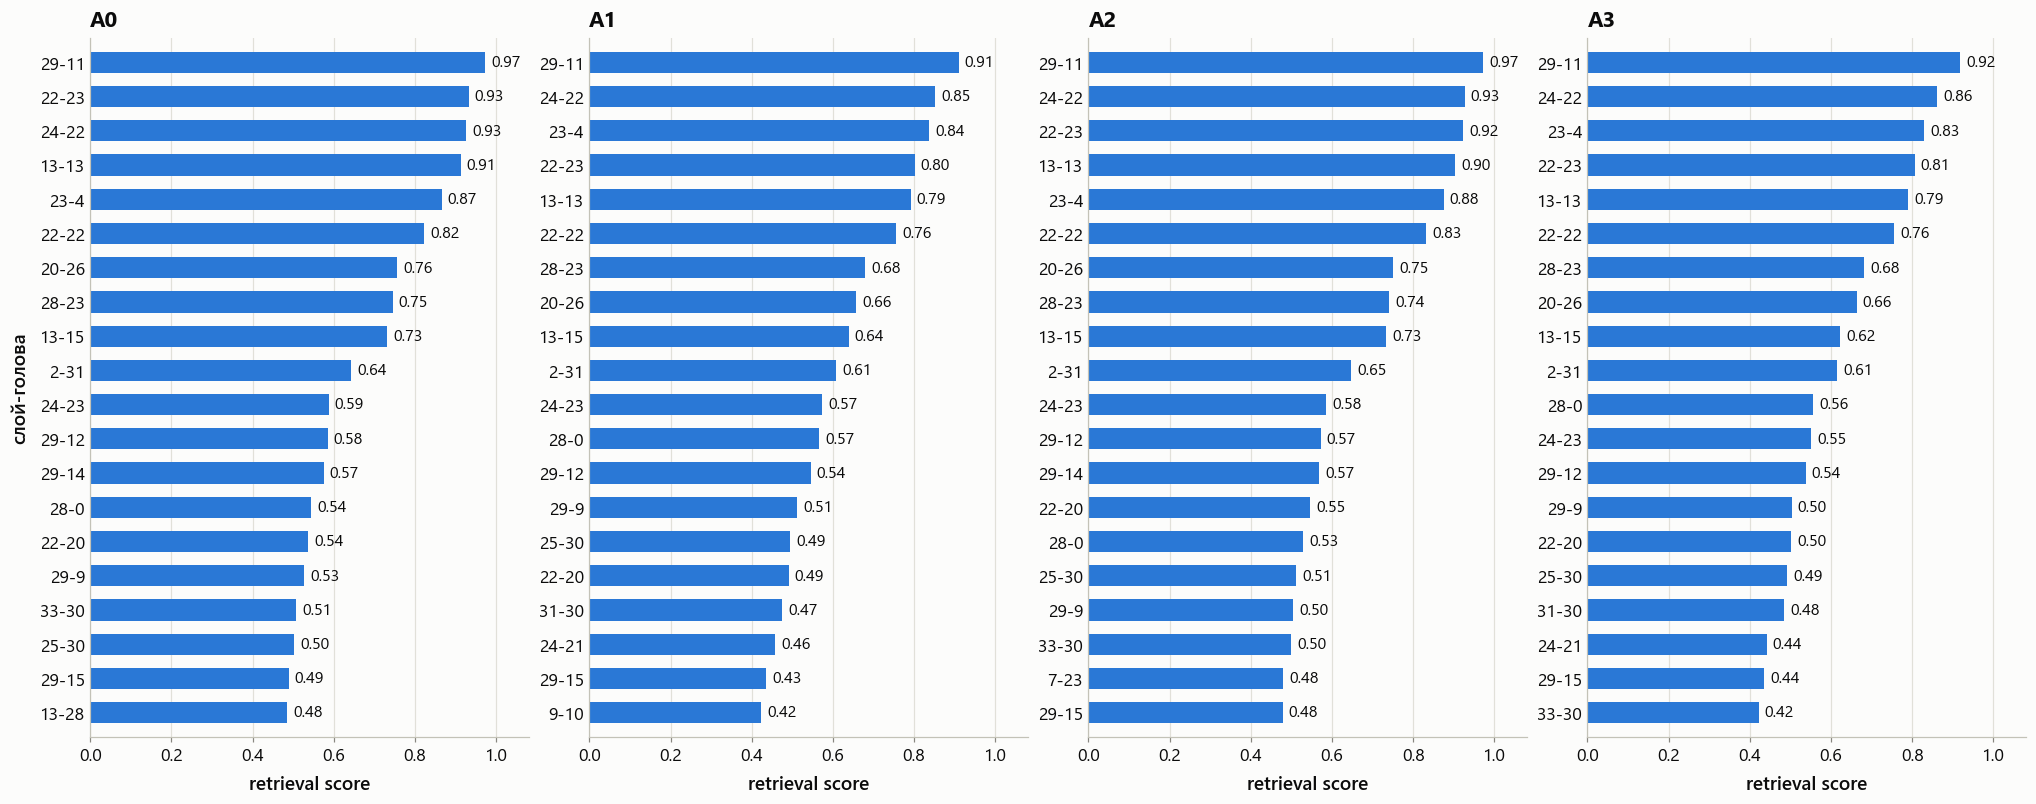

In [30]:
axes = panels(len(levels), 4.6, 7.2)
for ax, level in zip(axes, levels):
    plots.top_heads(rankings[level], k=20, threshold=THRESHOLD, ax=ax, title=level)
    if ax is not axes[0]:
        ax.set_ylabel("")
show(axes, "A_top_heads")

## 3.2. Сохраняется ли рейтинг детекции

Порядок голов на каждом уровне против порядка детекции на простой задаче: корреляция Спирмена по всем головам и число общих голов среди 20, 40 и 60 лучших. Строка A0 — это перенос на другие иглы без усложнения; остальные уровни сравниваются с ней.

In [31]:
display(hard.ranking_table(scores, reference))

print("то же против A0 (те же иглы, меняется только вопрос)")
display(hard.ranking_table({level: scores[level] for level in levels[1:]}, scores[levels[0]]))

,спирмен,top20,top40,top60
условие,,,,
A0,0.845,18/20,35/40,47/60
A1,0.834,17/20,35/40,47/60
A2,0.846,17/20,35/40,46/60
A3,0.839,17/20,35/40,47/60


то же против A0 (те же иглы, меняется только вопрос)


,спирмен,top20,top40,top60
условие,,,,
A1,0.946,17/20,38/40,55/60
A2,0.956,19/20,39/40,57/60
A3,0.946,18/20,38/40,55/60


### Корреляция скоров: исходные головы и наша задача

Точка — голова: по горизонтали её скор в детекции на простой задаче, по вертикали — на уровне оси A. На диагонали скор сохранён. Красные точки — головы, которые детекция относит к retrieval-головам (скор выше порога).

В углу и в таблице ниже: r — корреляция Пирсона (совпадают ли сами значения), ρ — Спирмена (совпадает ли порядок). По всем головам корреляцию во многом задают сотни голов со скором около нуля, поэтому отдельно посчитано по исходным retrieval-головам: по тем, что выше порога, и по 20, 40 и 60 лучшим.

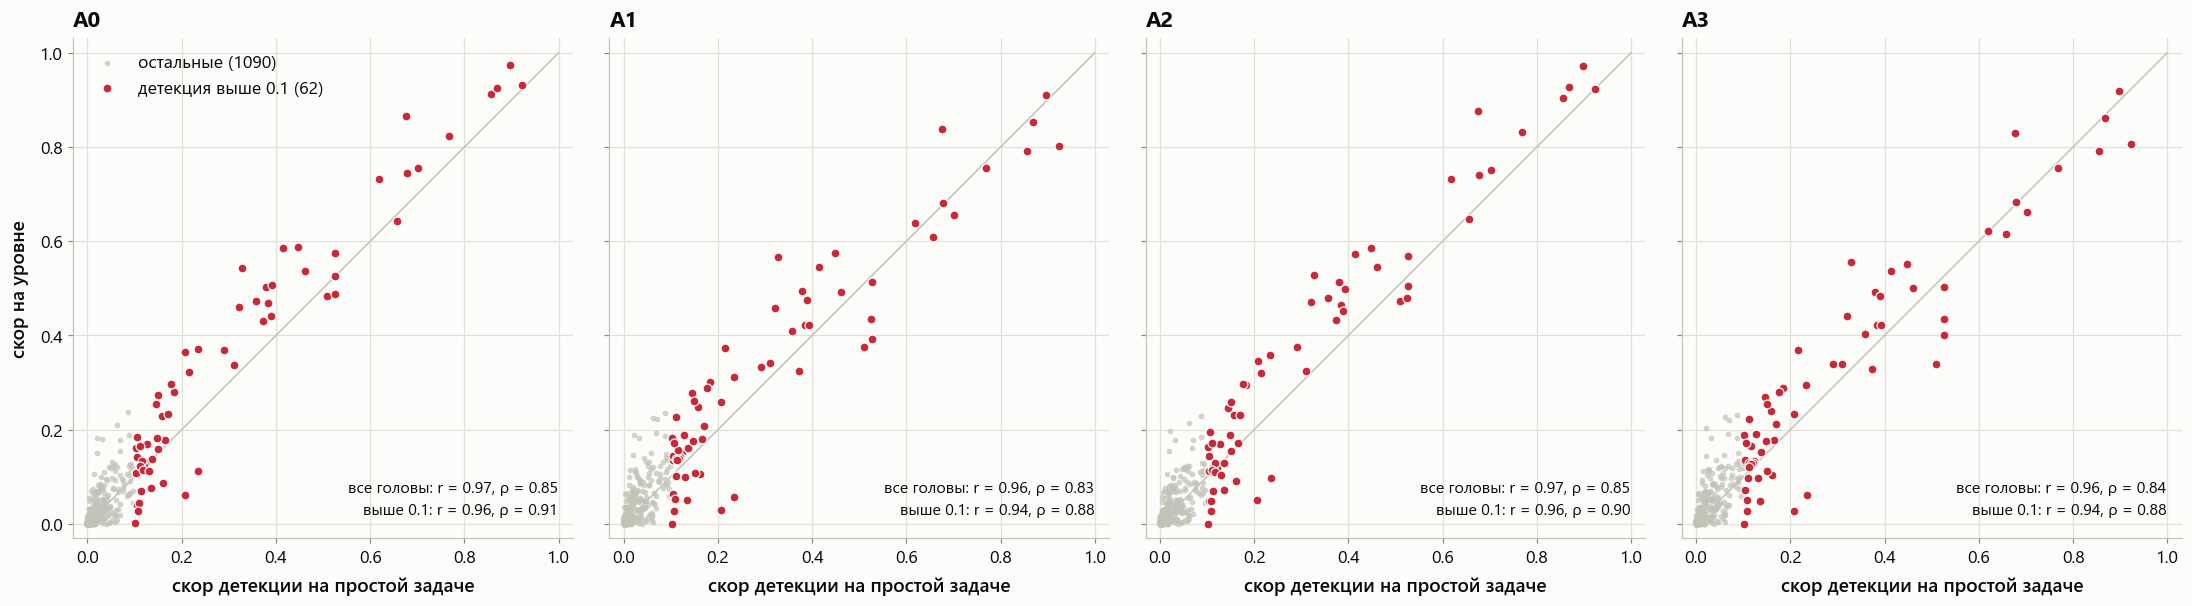

условие               A0                   A1                   A2         \
                   голов пирсон спирмен голов пирсон спирмен голов пирсон   
головы                                                                      
20 лучших детекции    20  0.943   0.908    20  0.883   0.836    20  0.938   
40 лучших детекции    40  0.949   0.945    40  0.911   0.911    40  0.947   
60 лучших детекции    60  0.962   0.915    60  0.936   0.888    60  0.961   
все головы          1152  0.974   0.845  1152  0.960   0.834  1152  0.973   
детекция выше 0.1     62  0.962   0.910    62  0.936   0.884    62  0.961   

условие                       A3                 
                   спирмен голов пирсон спирмен  
головы                                           
20 лучших детекции   0.905    20  0.886   0.839  
40 лучших детекции   0.940    40  0.917   0.905  
60 лучших детекции   0.907    60  0.940   0.882  
все головы           0.846  1152  0.961   0.839  
детекция выше 0.1    0.903    62  0.939   0.878

In [32]:
axes = panels(len(levels), 5.0, 5.2, sharey=True)
for ax, level in zip(axes, levels):
    plots.score_scatter(reference, scores[level], threshold=THRESHOLD, ax=ax, title=level)
    if ax is not axes[0]:
        ax.set_ylabel("")
        ax.get_legend().remove()
show(axes, "A_score_scatter")

display(hard.correlation_table(scores, reference, order, threshold=THRESHOLD).unstack("условие").swaplevel(axis=1).sort_index(axis=1, level=0, sort_remaining=False))

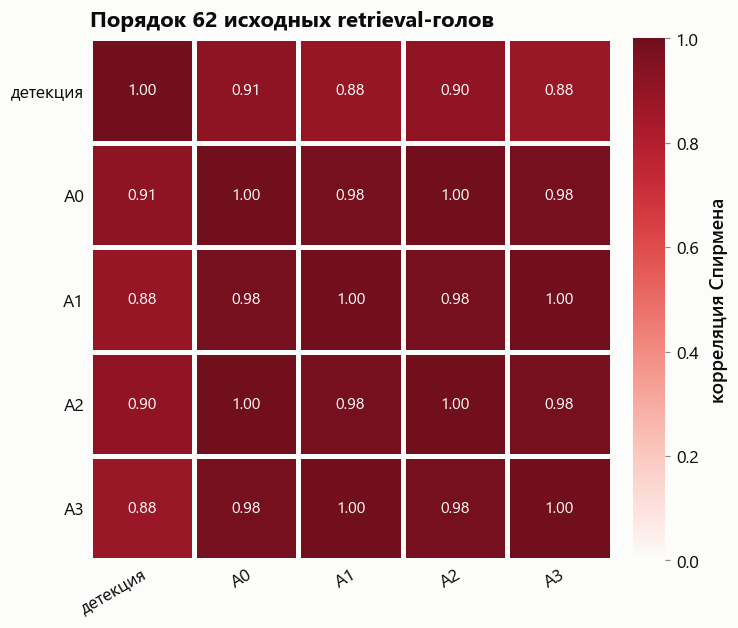

In [33]:
# между всеми условиями сразу: корреляция Спирмена по головам детекции выше порога
found = reference.ravel() > THRESHOLD
show(plots.correlation({"детекция": reference.ravel()[found], **{level: scores[level].ravel()[found] for level in levels}},
                       title=f"Порядок {int(found.sum())} исходных retrieval-голов"), "A_score_correlation")

## 3.3. Значения голов детекции по уровням

Головы стоят в порядке детекции и не переупорядочиваются. Если роль сохраняется, линии уровней идут вместе.

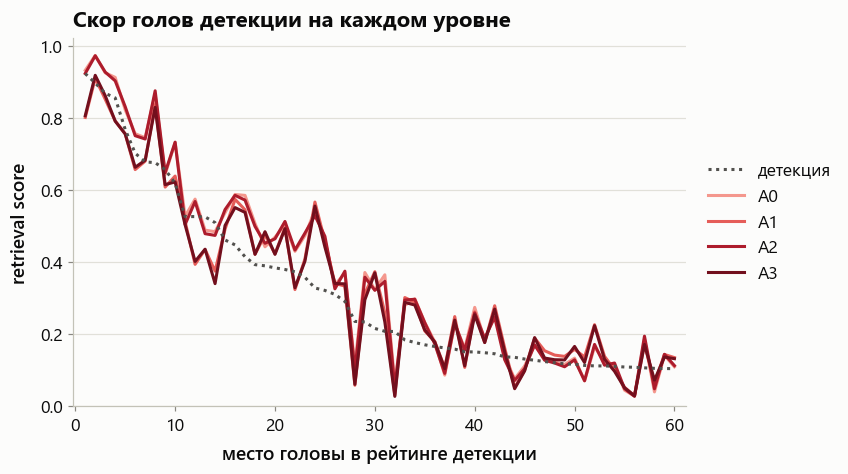

средний скор голов, которые отключаются масками


,детекция,A0,A1,A2,A3
20 лучших,0.6109,0.6754,0.6088,0.6723,0.6070
40 лучших,0.4248,0.4899,0.4458,0.4869,0.4423
60 лучших,0.3229,0.3675,0.3429,0.3653,0.3391


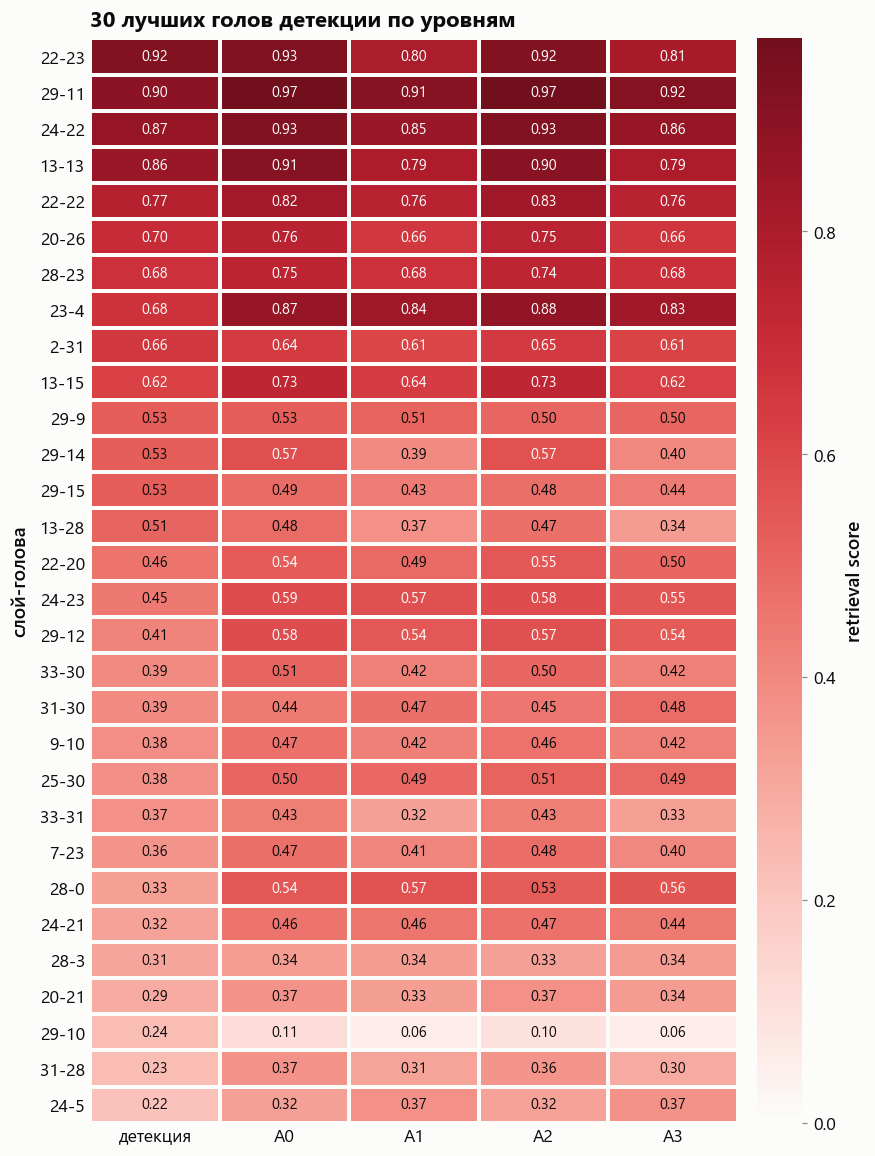

In [34]:
show(plots.rank_profile(scores, order, top=60, reference=reference, title="Скор голов детекции на каждом уровне"), "A_rank_profile")

print("средний скор голов, которые отключаются масками")
display(hard.top_means({"детекция": reference, **scores}, order))

top = 30
table = pd.DataFrame({"детекция": reference.ravel()[order[:top]], **{level: scores[level].ravel()[order[:top]] for level in levels}},
                     index=[heads.name(i) for i in order[:top]])
show(plots.head_table(table, title=f"{top} лучших голов детекции по уровням"), "A_head_table")

## 3.4. Контроль: дословные ответы

Скор копирования засчитывает шаг, только если голова смотрит на токен иглы и модель выдаёт именно его. Если модель пересказывает ответ, скопированных токенов меньше, и скор падает без всякой смены голов. Поэтому тот же расчёт повторён только на ответах с точной фразой: там число скопированных токенов одинаково на всех уровнях.

ответов с точной фразой: {'A0': 198, 'A1': 128, 'A2': 198, 'A3': 108}


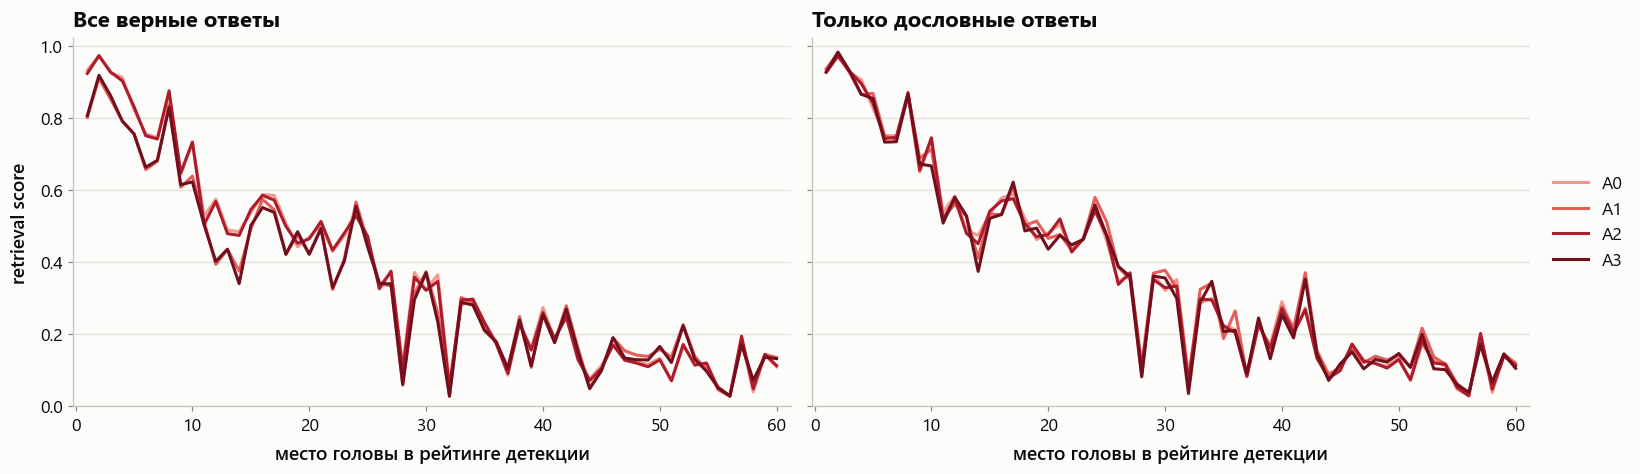

средний скор лучших голов детекции: все верные ответы


,A0,A1,A2,A3
20 лучших,0.6754,0.6088,0.6723,0.6070
40 лучших,0.4899,0.4458,0.4869,0.4423
60 лучших,0.3675,0.3429,0.3653,0.3391


только дословные ответы


,A0,A1,A2,A3
20 лучших,0.6780,0.6753,0.6743,0.6655
40 лучших,0.4928,0.4948,0.4891,0.4844
60 лучших,0.3703,0.3764,0.3677,0.3667


In [35]:
exact = heads.samples["exact"].to_numpy()
print("ответов с точной фразой:", {level: int((exact & heads.samples["correct"] & (heads.samples["level"] == level)).sum()) for level in levels})
exact_scores = hard.level_scores(heads, METRIC, where=exact)

axes = panels(2, 6.6, extra=1.6, sharey=True)
plots.rank_profile(scores, order, top=60, legend=False, ax=axes[0], title="Все верные ответы")
plots.rank_profile(exact_scores, order, top=60, ax=axes[1], title="Только дословные ответы")
axes[1].set_ylabel("")
show(axes, "A_exact_control")

print("средний скор лучших голов детекции: все верные ответы")
display(hard.top_means(scores, order))
print("только дословные ответы")
display(hard.top_means(exact_scores, order))

## 3.5. Куда головы смотрят: масса внимания

Масса не зависит от формулировки ответа. Головы стоят в порядке детекции (по копированию).

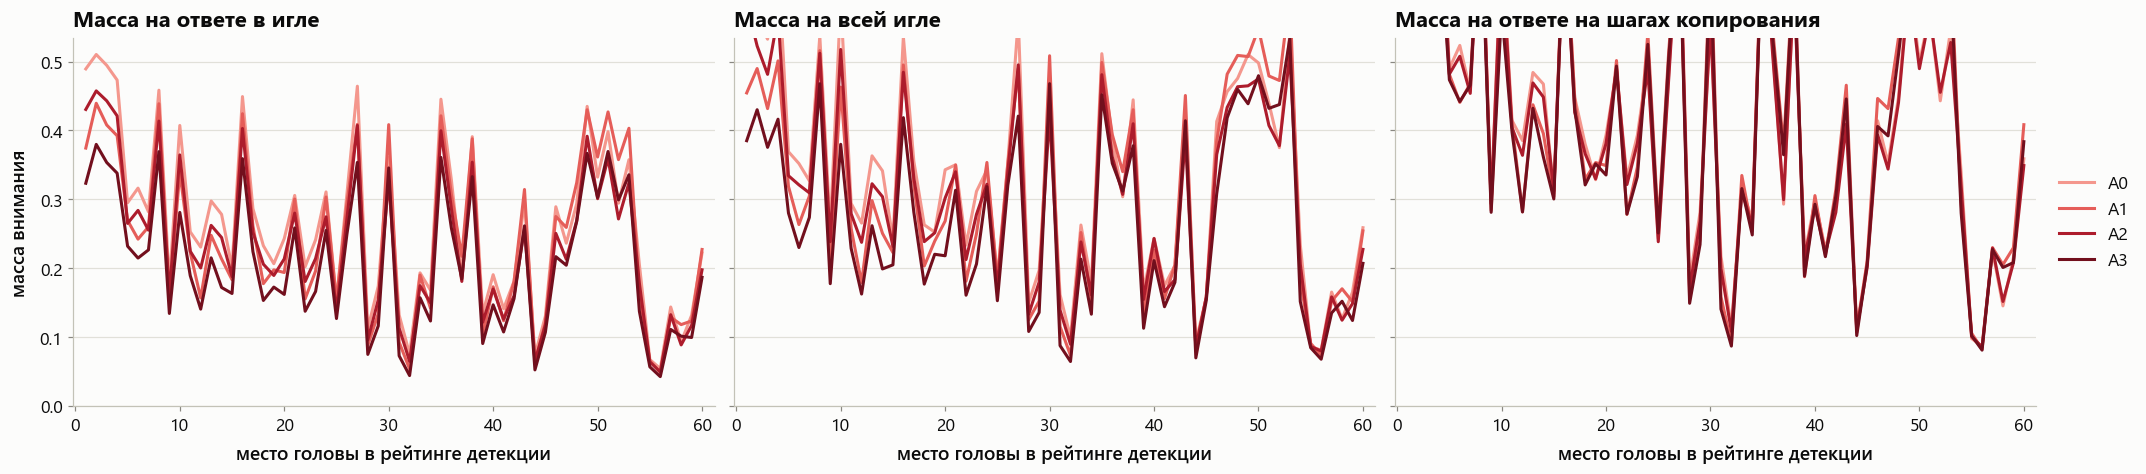

Масса на ответе в игле (needle_mass): среднее у лучших голов детекции


,A0,A1,A2,A3
20 лучших,0.3291,0.2800,0.2940,0.2403
40 лучших,0.2866,0.2533,0.2560,0.2166
60 лучших,0.2640,0.2441,0.2363,0.2075


Масса на всей игле (needle_sentence_mass): среднее у лучших голов детекции


,A0,A1,A2,A3
20 лучших,0.4045,0.3344,0.3685,0.2895
40 лучших,0.3495,0.3062,0.3214,0.2678
60 лучших,0.3309,0.3059,0.3061,0.2684


Масса на ответе на шагах копирования (needle_attention_mass): среднее у лучших голов детекции


,A0,A1,A2,A3
20 лучших,0.5400,0.5011,0.5274,0.4902
40 лучших,0.4641,0.4468,0.4541,0.4361
60 лучших,0.4200,0.4203,0.4110,0.4081


In [36]:
mass_metrics = {"needle_mass": "Масса на ответе в игле", "needle_sentence_mass": "Масса на всей игле", "needle_attention_mass": "Масса на ответе на шагах копирования"}
masses = {metric: hard.level_scores(heads, metric, where=common) for metric in mass_metrics}

axes = panels(3, 6.0, extra=1.4, sharey=True)
for ax, (metric, name) in zip(axes, mass_metrics.items()):
    plots.rank_profile(masses[metric], order, top=60, ylabel="масса внимания", legend=ax is axes[-1], ax=ax, title=name)
    if ax is not axes[0]:
        ax.set_ylabel("")
show(axes, "A_mass_profile")

for metric, name in mass_metrics.items():
    print(f"{name} ({metric}): среднее у лучших голов детекции")
    display(hard.top_means(masses[metric], order))

## 3.6. По семействам

Совпадает ли направление эффекта в каждом семействе: средний скор 20 лучших голов детекции по уровням.

,A0,A1,A2,A3
cairo,0.6670,0.5171,0.6550,0.5283
lisbon,0.6815,0.6888,0.6833,0.6852
oslo,0.6791,0.6274,0.6825,0.6080


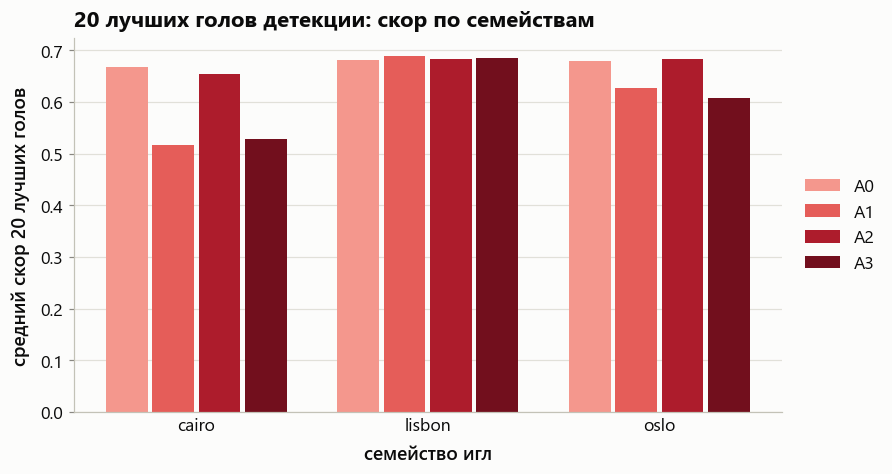

In [37]:
family_top = pd.DataFrame({family: hard.top_means(hard.level_scores(heads, METRIC, where=common & (heads.samples["family"] == family).to_numpy()), order).loc["20 лучших"]
                           for family in families}).T
display(family_top)
show(plots.group_bars(family_top, xlabel="семейство игл", ylabel="средний скор 20 лучших голов", title="20 лучших голов детекции: скор по семействам"), "A_family_top20")

## 3.7. Появляются ли новые головы

Головы, которые на уровне входят в 20 лучших, но в детекции стояли за пределами первых 60.

In [38]:
place = {int(i): rank + 1 for rank, i in enumerate(order)}
rows = []
for level in levels:
    for i in np.argsort(-scores[level].ravel(), kind="stable")[:20]:
        if place[int(i)] > 60:
            rows.append({"уровень": level, "голова": heads.name(i), "место в детекции": place[int(i)], "скор детекции": round(float(reference.ravel()[i]), 3),
                         **{l: round(float(scores[l].ravel()[i]), 3) for l in levels}})
pd.DataFrame(rows) if rows else print("таких голов нет")

таких голов нет
